In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
df = pd.read_csv("data/netflix_user_behavior_dataset.csv")

In [3]:
df

,user_id,age,gender,country,account_age_months,subscription_type,monthly_fee,payment_method,primary_device,devices_used,favorite_genre,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,churned
0,U100000,56,Male,India,17,Standard,15.99,PayPal,Laptop,1,Sci-Fi,220,17,3,60,1.7,5,66,16,No
1,U100001,46,Female,USA,20,Standard,12.99,PayPal,Tablet,2,Documentary,76,15,4,71,4.6,7,78,14,No
2,U100002,32,Other,USA,25,Basic,15.99,PayPal,Tablet,2,Comedy,215,6,13,33,2.0,27,29,41,No
3,U100003,60,Male,Canada,37,Standard,12.99,PayPal,Smart TV,3,Action,280,4,9,58,1.2,9,23,22,No
4,U100004,25,Male,Brazil,23,Premium,12.99,PayPal,Mobile,3,Horror,261,15,9,64,1.3,49,56,54,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,U149995,60,Female,Japan,30,Standard,15.99,UPI,Tablet,1,Documentary,178,19,1,45,1.8,13,43,8,No
49996,U149996,46,Other,Brazil,39,Standard,12.99,PayPal,Smart TV,3,Comedy,95,15,5,77,2.1,46,11,30,Yes
49997,U149997,19,Male,UK,53,Basic,7.99,Credit Card,Tablet,3,Thriller,118,18,4,44,2.3,26,17,16,No
49998,U149998,43,Female,UK,19,Standard,7.99,PayPal,Laptop,1,Thriller,280,2,4,44,2.4,12,4,31,No


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   user_id                    50000 non-null  object 
 1   age                        50000 non-null  int64  
 2   gender                     50000 non-null  object 
 3   country                    50000 non-null  object 
 4   account_age_months         50000 non-null  int64  
 5   subscription_type          50000 non-null  object 
 6   monthly_fee                50000 non-null  float64
 7   payment_method             50000 non-null  object 
 8   primary_device             50000 non-null  object 
 9   devices_used               50000 non-null  int64  
 10  favorite_genre             50000 non-null  object 
 11  avg_watch_time_minutes     50000 non-null  int64  
 12  watch_sessions_per_week    50000 non-null  int64  
 13  binge_watch_sessions       50000 non-null  int

In [5]:
df.isnull().sum()

user_id                      0
age                          0
gender                       0
country                      0
account_age_months           0
subscription_type            0
monthly_fee                  0
payment_method               0
primary_device               0
devices_used                 0
favorite_genre               0
avg_watch_time_minutes       0
watch_sessions_per_week      0
binge_watch_sessions         0
completion_rate              0
rating_given                 0
content_interactions         0
recommendation_click_rate    0
days_since_last_login        0
churned                      0
dtype: int64

In [6]:
df["country"].unique()

array(['India', 'USA', 'Canada', 'Brazil', 'France', 'Australia', 'UK',
       'Japan', 'Germany', 'Spain'], dtype=object)

In [7]:
netflix_data= df.iloc[:,1:]

In [8]:
netflix_data

,age,gender,country,account_age_months,subscription_type,monthly_fee,payment_method,primary_device,devices_used,favorite_genre,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,churned
0,56,Male,India,17,Standard,15.99,PayPal,Laptop,1,Sci-Fi,220,17,3,60,1.7,5,66,16,No
1,46,Female,USA,20,Standard,12.99,PayPal,Tablet,2,Documentary,76,15,4,71,4.6,7,78,14,No
2,32,Other,USA,25,Basic,15.99,PayPal,Tablet,2,Comedy,215,6,13,33,2.0,27,29,41,No
3,60,Male,Canada,37,Standard,12.99,PayPal,Smart TV,3,Action,280,4,9,58,1.2,9,23,22,No
4,25,Male,Brazil,23,Premium,12.99,PayPal,Mobile,3,Horror,261,15,9,64,1.3,49,56,54,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,60,Female,Japan,30,Standard,15.99,UPI,Tablet,1,Documentary,178,19,1,45,1.8,13,43,8,No
49996,46,Other,Brazil,39,Standard,12.99,PayPal,Smart TV,3,Comedy,95,15,5,77,2.1,46,11,30,Yes
49997,19,Male,UK,53,Basic,7.99,Credit Card,Tablet,3,Thriller,118,18,4,44,2.3,26,17,16,No
49998,43,Female,UK,19,Standard,7.99,PayPal,Laptop,1,Thriller,280,2,4,44,2.4,12,4,31,No


In [9]:
num_var = ["age","account_age_months","monthly_fee","avg_watch_time_minutes","watch_sessions_per_week","binge_watch_sessions","completion_rate","rating_given","content_interactions","recommendation_click_rate","days_since_last_login"]

In [10]:
cat_var = ["gender","country","devices_used","subscription_type","payment_method","primary_device","favorite_genre","churned"]

In [11]:
for i in range(len(cat_var)):
    unique_val = netflix_data[cat_var[i]].unique()
    print(f"{cat_var[i]} :: {unique_val}")
    print(f"Number of unique value of {cat_var[i]} is : {len(unique_val)}")

gender :: ['Male' 'Female' 'Other']
Number of unique value of gender is : 3
country :: ['India' 'USA' 'Canada' 'Brazil' 'France' 'Australia' 'UK' 'Japan'
 'Germany' 'Spain']
Number of unique value of country is : 10
devices_used :: [1 2 3]
Number of unique value of devices_used is : 3
subscription_type :: ['Standard' 'Basic' 'Premium']
Number of unique value of subscription_type is : 3
payment_method :: ['PayPal' 'Credit Card' 'UPI' 'Debit Card']
Number of unique value of payment_method is : 4
primary_device :: ['Laptop' 'Tablet' 'Smart TV' 'Mobile']
Number of unique value of primary_device is : 4
favorite_genre :: ['Sci-Fi' 'Documentary' 'Comedy' 'Action' 'Horror' 'Romance' 'Thriller'
 'Drama']
Number of unique value of favorite_genre is : 8
churned :: ['No' 'Yes']
Number of unique value of churned is : 2


In [12]:
def cat_plot(var):
    plot = netflix_data[var].value_counts().plot(kind="bar",figsize=(7,4))
    plt.title(f"Distribution of {var}")
    plt.xlabel(var)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()
    

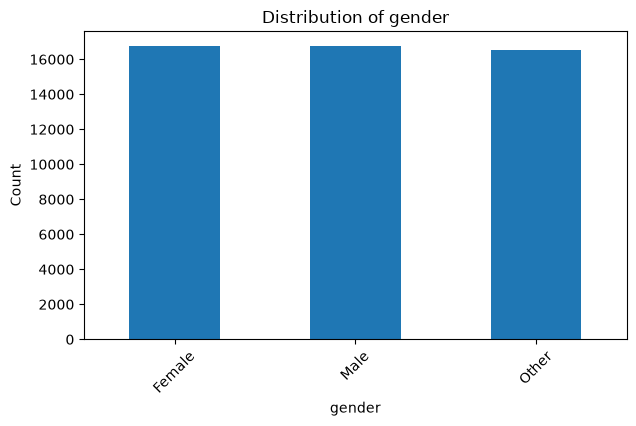

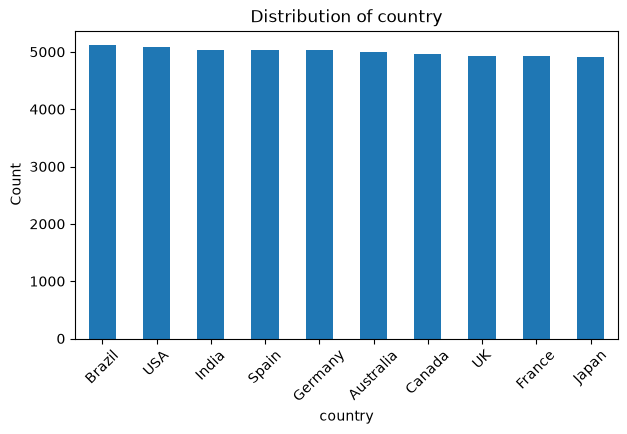

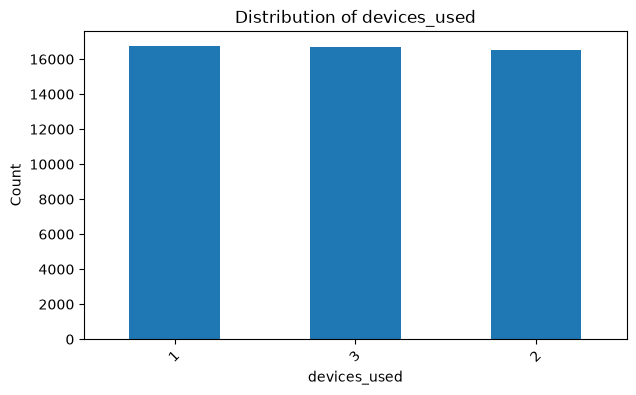

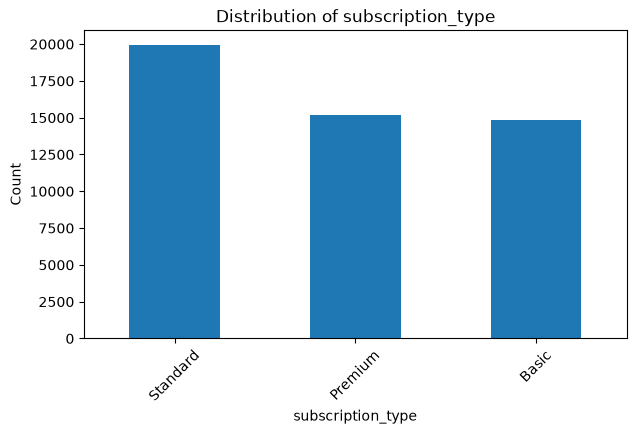

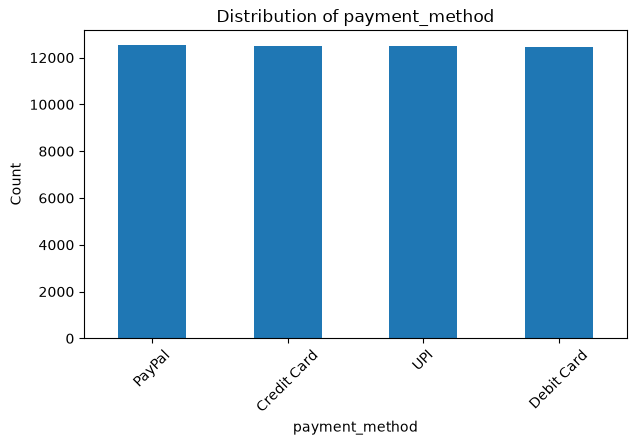

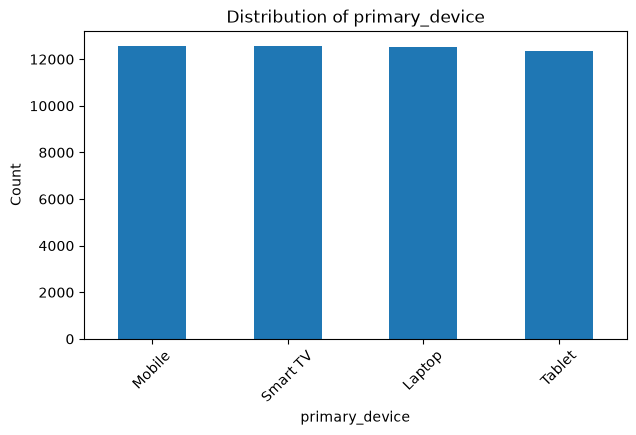

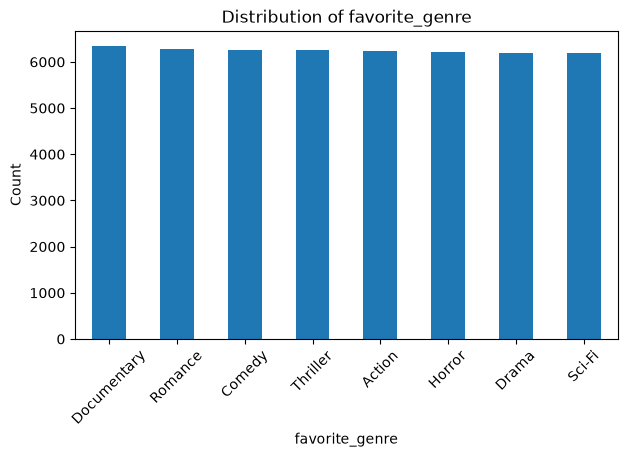

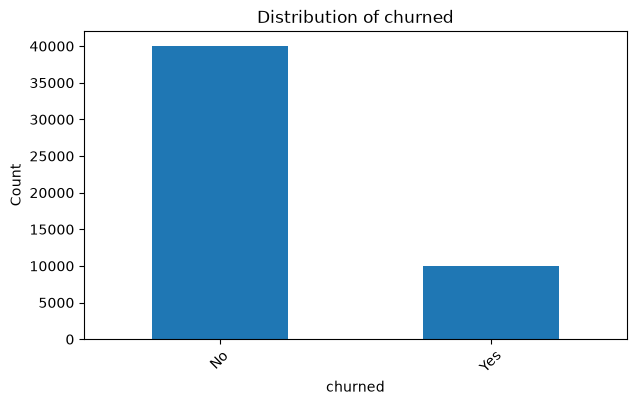

In [13]:
for i in range(len(cat_var)):
    cat_plot(cat_var[i])
    

In [14]:
def num_plot(var):
    plt.figure(figsize=(14,5))
    
    ## distribution plot
    plt.subplot(1,2,1)
    sns.distplot(netflix_data[var],bins = 20)
    plt.title(f"Distribution Plot of {var}")
    plt.xlabel(var)
    
    ## Q-Q Plot
    plt.subplot(1,2,2)
    stats.probplot(netflix_data[var] , dist="norm",plot=plt)
    plt.title(f"Q-Q Plot of {var}")
    
    plt.tight_layout()
    plt.show()

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


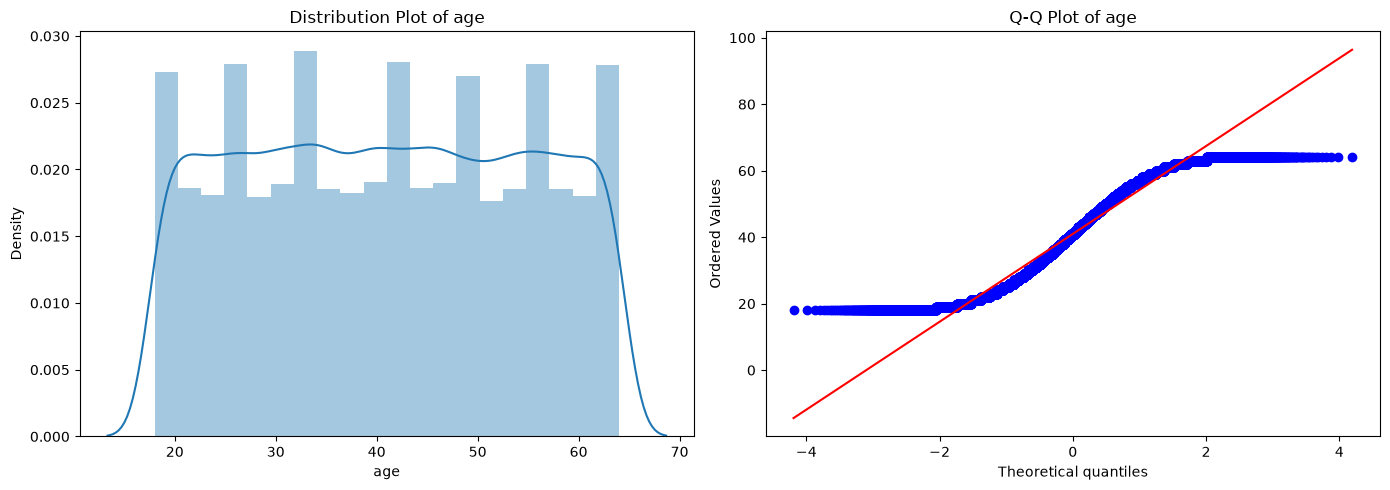

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


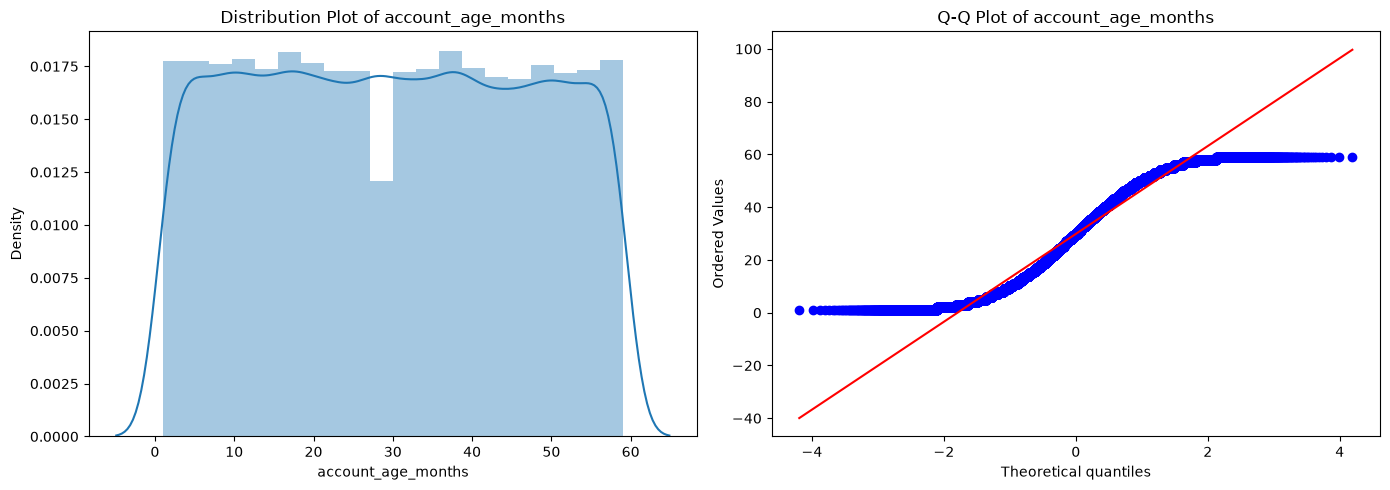

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


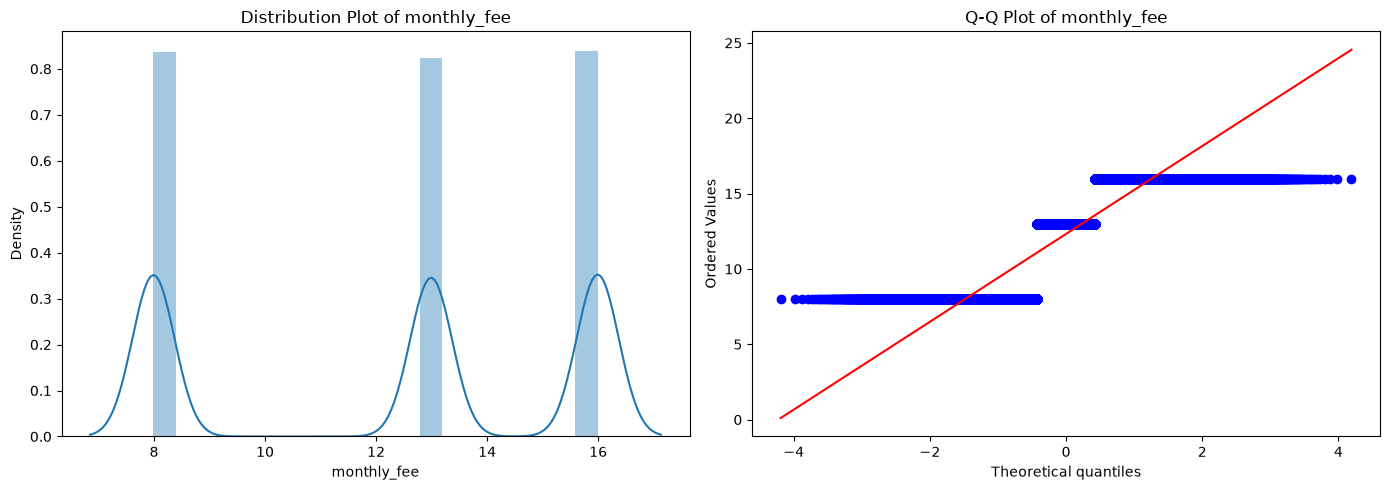

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


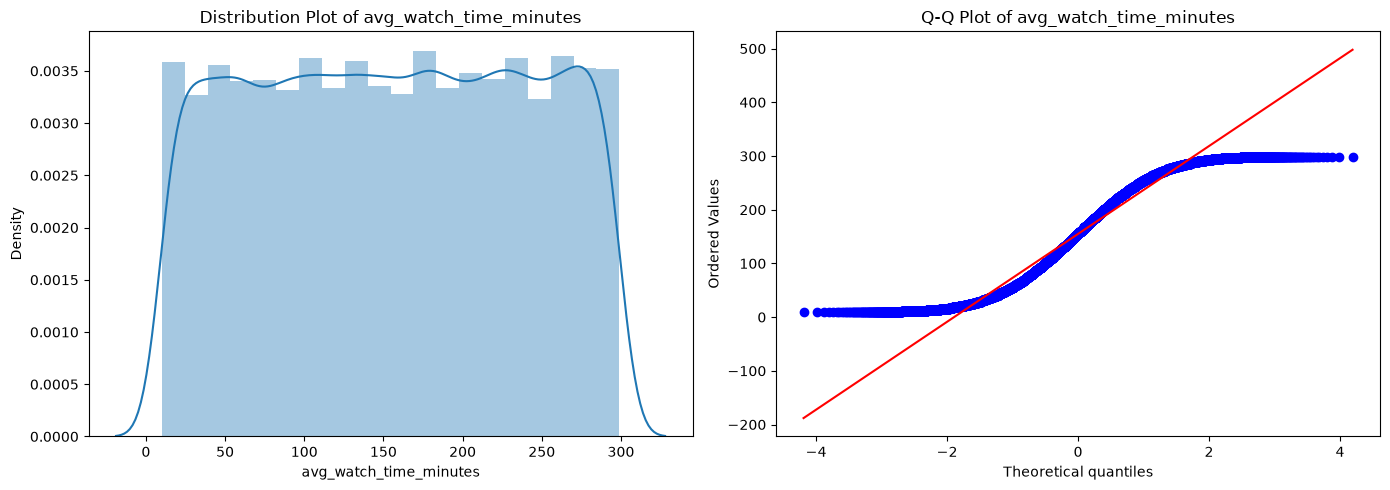

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


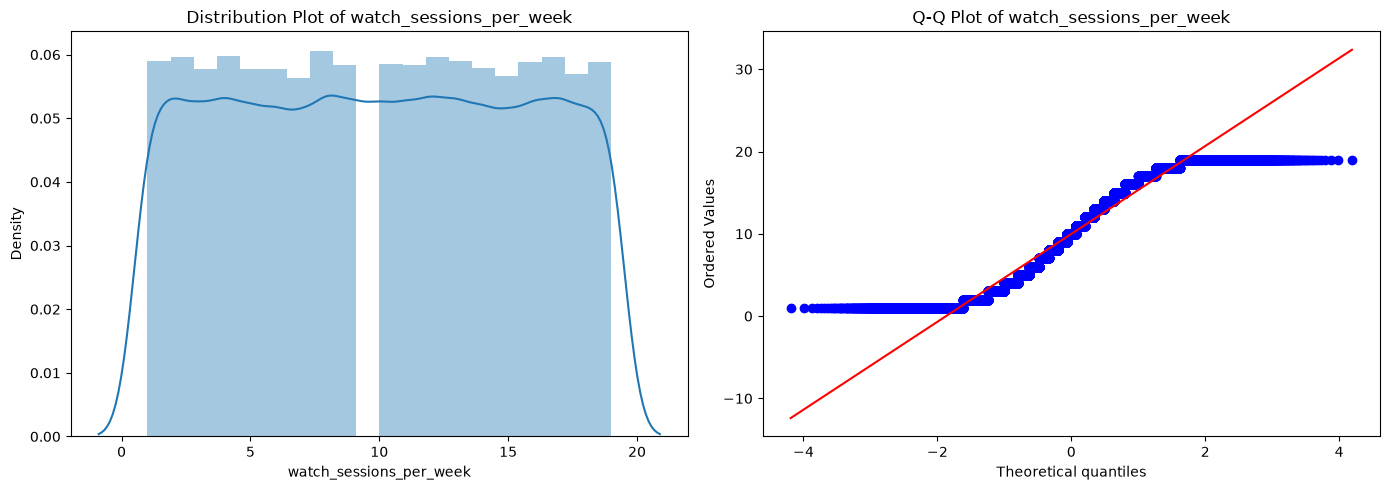

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


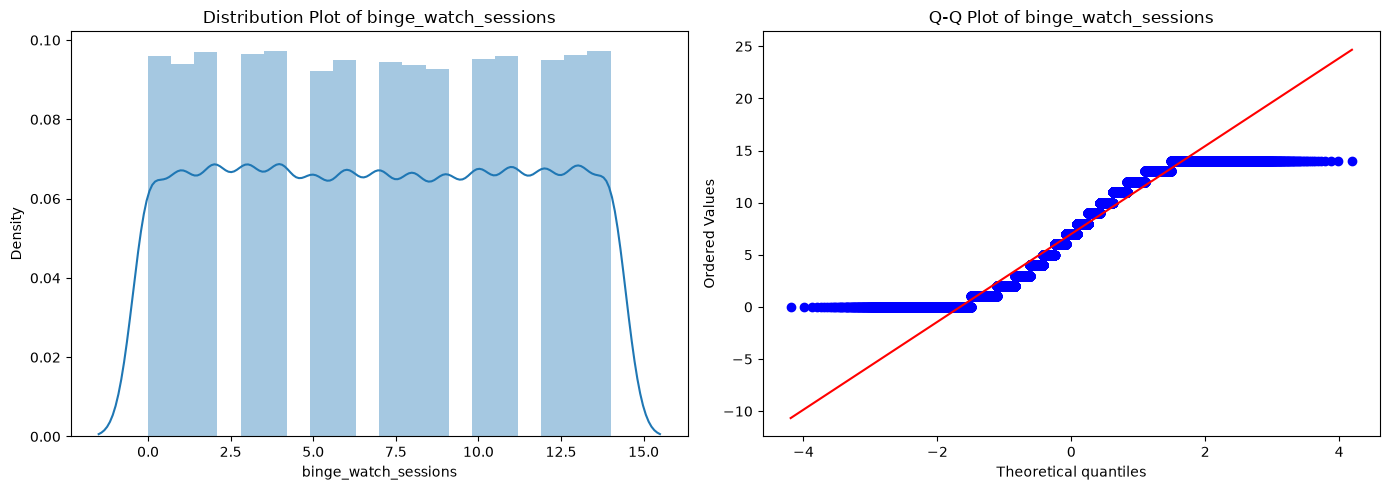

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


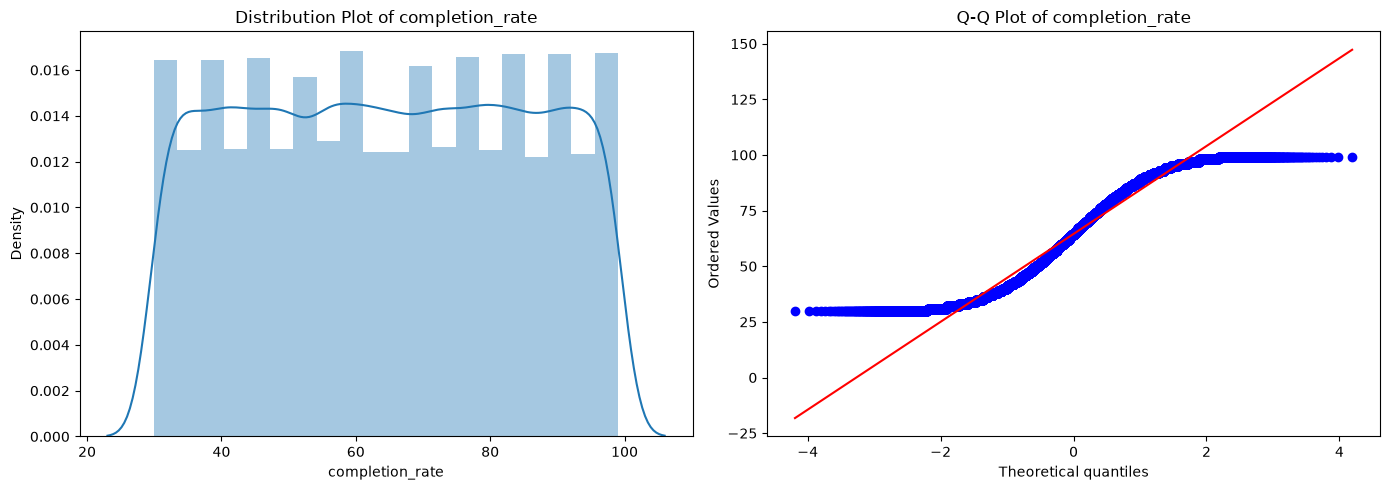

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


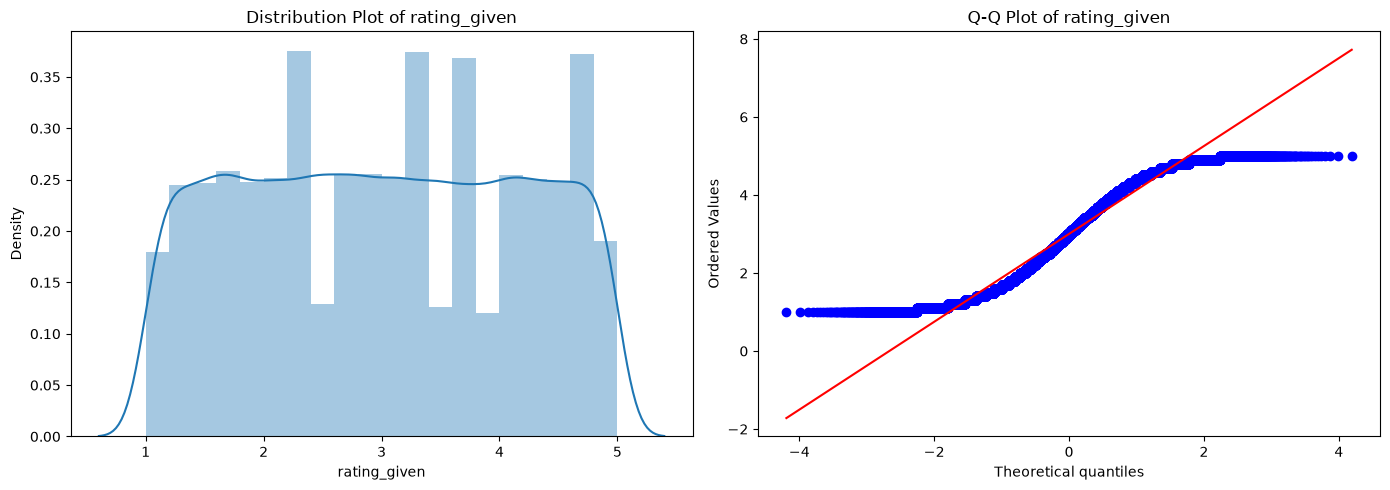

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


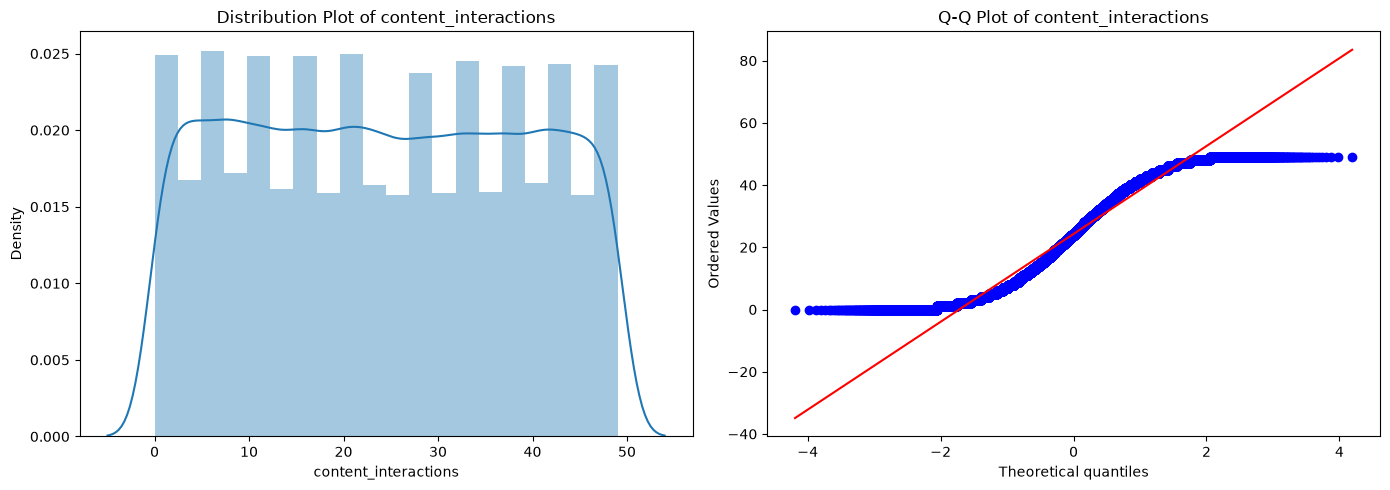

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


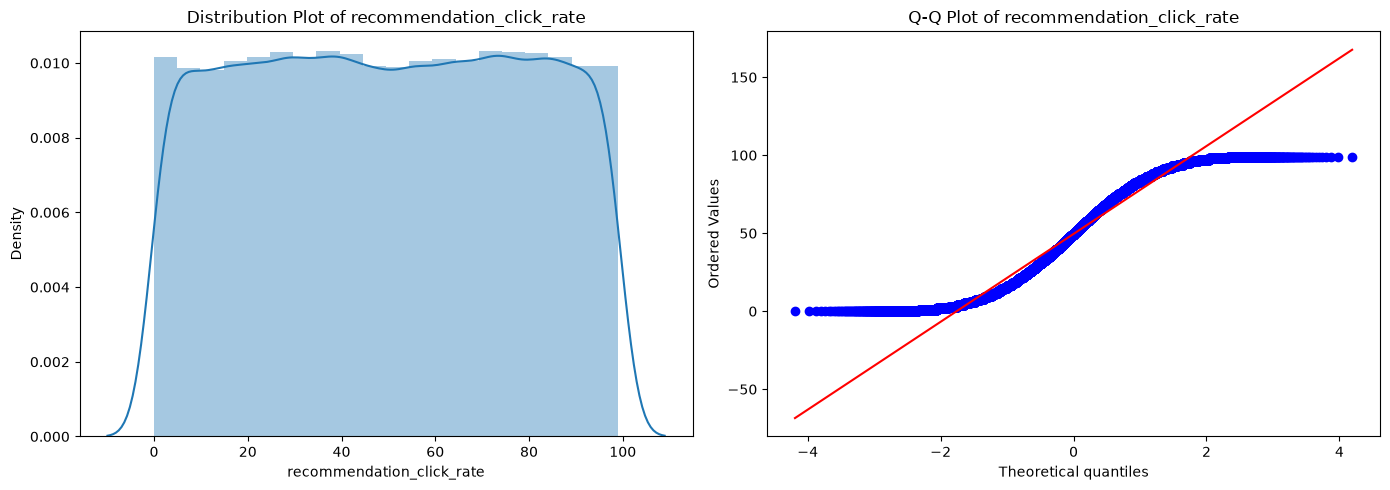

C:\Users\Saikat Maiti\AppData\Local\Temp\ipykernel_24772\3568827262.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(netflix_data[var],bins = 20)
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


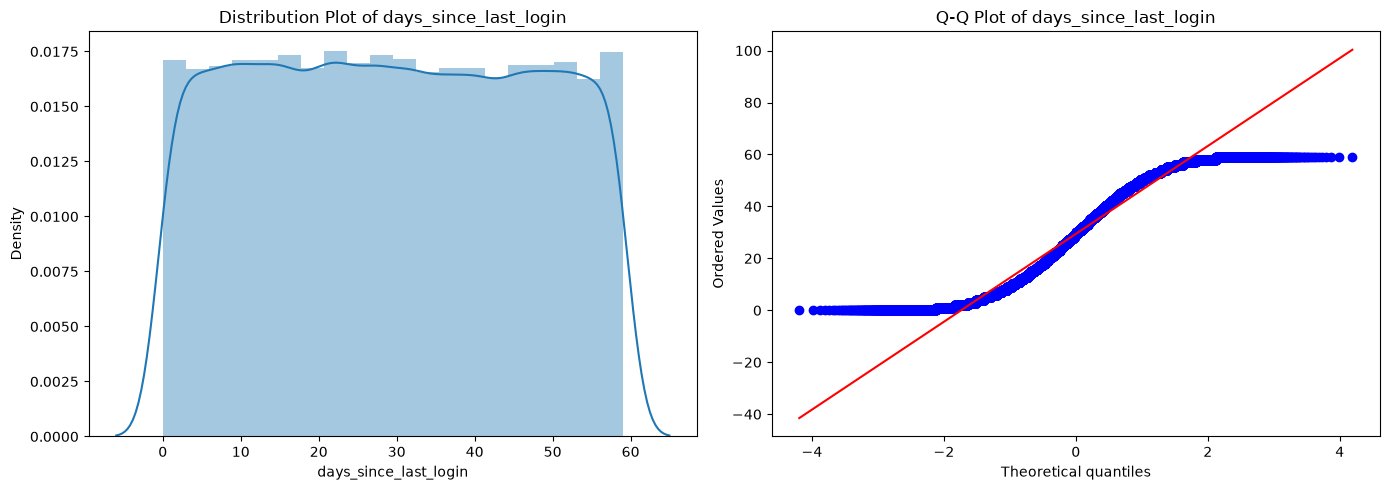

In [15]:
for col in range(len(num_var)):
    num_plot(num_var[col])

In [16]:
from scipy.stats import shapiro

stat, p_value = shapiro(netflix_data["account_age_months"].dropna())

print("Shapiro Statistic:", stat)
print("P-value:", p_value)

if p_value > 0.05:
    print("Approximately normally distributed")
else:
    print("Not normally distributed")

Shapiro Statistic: 0.9540517567446583
P-value: 2.2568929633106577e-78
Not normally distributed


C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 50000.
  res = hypotest_fun_out(*samples, **kwds)


In [17]:
from scipy.stats import shapiro
def norm_test(var):
    stat, p_value = shapiro(netflix_data[var])
    print(f"Shapiro Statistic of {var}:", stat)
    print(f"P-value of {var}:", p_value)

    if p_value > 0.05:
        print("Approximately normally distributed")
    else:
        print("Not normally distributed")

In [18]:
for col in range(len(num_var)):
    norm_test(num_var[col])

Shapiro Statistic of age: 0.9545717726890709
P-value of age: 4.078125691412792e-78
Not normally distributed
Shapiro Statistic of account_age_months: 0.9540517567446583
P-value of account_age_months: 2.2568929633106577e-78
Not normally distributed
Shapiro Statistic of monthly_fee: 0.7761839587876727
P-value of monthly_fee: 2.5291435249854872e-118
Not normally distributed
Shapiro Statistic of avg_watch_time_minutes: 0.9548483332448593
P-value of avg_watch_time_minutes: 5.599344594154875e-78
Not normally distributed
Shapiro Statistic of watch_sessions_per_week: 0.9488266872138557
P-value of watch_sessions_per_week: 7.956904589029816e-81
Not normally distributed
Shapiro Statistic of binge_watch_sessions: 0.9445450287396329
P-value of binge_watch_sessions: 1.1108291681692386e-82
Not normally distributed
Shapiro Statistic of completion_rate: 0.9543522887301046
P-value of completion_rate: 3.174718617627121e-78
Not normally distributed
Shapiro Statistic of rating_given: 0.9552892181617564
P-va

In [19]:
netflix_data[num_var].describe()

,age,account_age_months,monthly_fee,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,40.979240,29.874000,12.323340,154.946520,9.986920,7.002520,64.533420,3.002316,24.306380,49.563000,29.410520
std,13.528733,17.051104,3.309109,83.727292,5.480616,4.335819,20.206377,1.152308,14.468037,28.816997,17.312414
min,18.000000,1.000000,7.990000,10.000000,1.000000,0.000000,30.000000,1.000000,0.000000,0.000000,0.000000
25%,29.000000,15.000000,7.990000,83.000000,5.000000,3.000000,47.000000,2.000000,12.000000,25.000000,14.000000
50%,41.000000,30.000000,12.990000,155.000000,10.000000,7.000000,65.000000,3.000000,24.000000,50.000000,29.000000
75%,53.000000,45.000000,15.990000,228.000000,15.000000,11.000000,82.000000,4.000000,37.000000,75.000000,44.000000
max,64.000000,59.000000,15.990000,299.000000,19.000000,14.000000,99.000000,5.000000,49.000000,99.000000,59.000000


In [20]:
## check skewness

In [21]:
skewness = netflix_data[num_var].skew().sort_values(ascending=False)

print(skewness)

content_interactions         0.018385
days_since_last_login        0.012781
account_age_months           0.011984
age                          0.007921
rating_given                 0.005160
binge_watch_sessions         0.003289
watch_sessions_per_week      0.000819
completion_rate             -0.001427
recommendation_click_rate   -0.003152
avg_watch_time_minutes      -0.008868
monthly_fee                 -0.292348
dtype: float64


In [22]:
netflix_data["account_age_months_log"] = np.log1p(
    netflix_data["account_age_months"]
)

C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


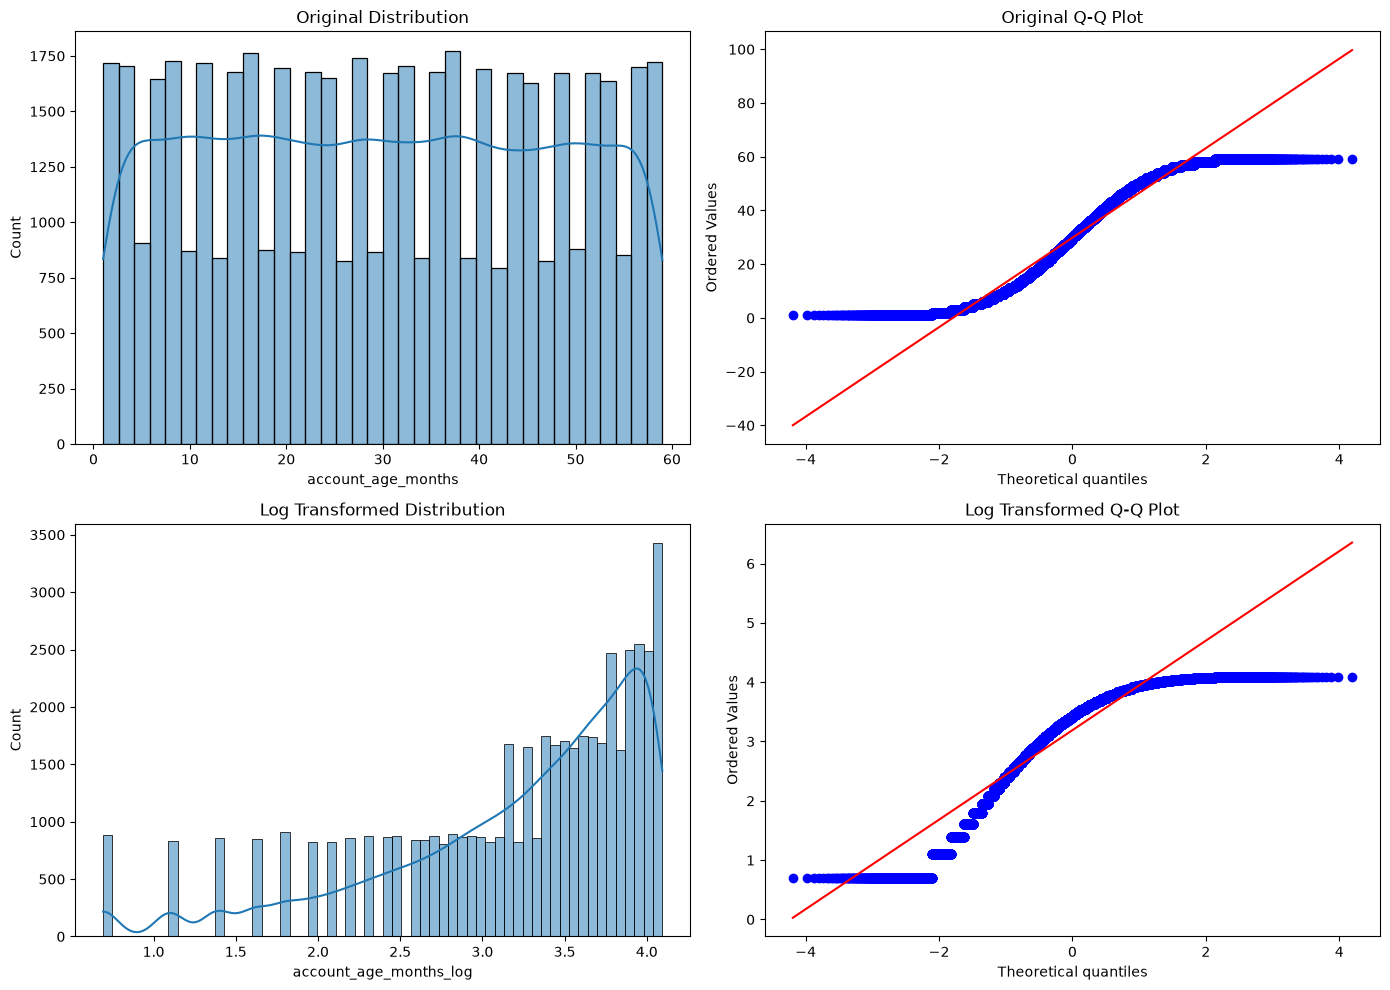

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Original distribution
sns.histplot(netflix_data["account_age_months"], kde=True, ax=ax[0, 0])
ax[0, 0].set_title("Original Distribution")

# Original Q-Q plot
stats.probplot(
    netflix_data["account_age_months"].dropna(),
    dist="norm",
    plot=ax[0, 1]
)
ax[0, 1].set_title("Original Q-Q Plot")

# Log-transformed distribution
sns.histplot(netflix_data["account_age_months_log"], kde=True, ax=ax[1, 0])
ax[1, 0].set_title("Log Transformed Distribution")

# Transformed Q-Q plot
stats.probplot(
    netflix_data["account_age_months_log"].dropna(),
    dist="norm",
    plot=ax[1, 1]
)
ax[1, 1].set_title("Log Transformed Q-Q Plot")

plt.tight_layout()
plt.show()

In [24]:
skewness = netflix_data[num_var].skew().sort_values(ascending=False)

print(skewness)

content_interactions         0.018385
days_since_last_login        0.012781
account_age_months           0.011984
age                          0.007921
rating_given                 0.005160
binge_watch_sessions         0.003289
watch_sessions_per_week      0.000819
completion_rate             -0.001427
recommendation_click_rate   -0.003152
avg_watch_time_minutes      -0.008868
monthly_fee                 -0.292348
dtype: float64


In [25]:
print("Original Skewness:",
      netflix_data["account_age_months"].skew())

print("Log Skewness:",
      netflix_data["account_age_months_log"].skew())

Original Skewness: 0.011984398459399302
Log Skewness: -1.1716868146729151


In [26]:
print(netflix_data[
    ["account_age_months", "account_age_months_log"]
].describe())

       account_age_months  account_age_months_log
count        50000.000000            50000.000000
mean            29.874000                3.191030
std             17.051104                0.803713
min              1.000000                0.693147
25%             15.000000                2.772589
50%             30.000000                3.433987
75%             45.000000                3.828641
max             59.000000                4.094345


In [27]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method="yeo-johnson")

netflix_data["account_age_months_yeo"] = pt.fit_transform(
    netflix_data[["account_age_months"]]
)

C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


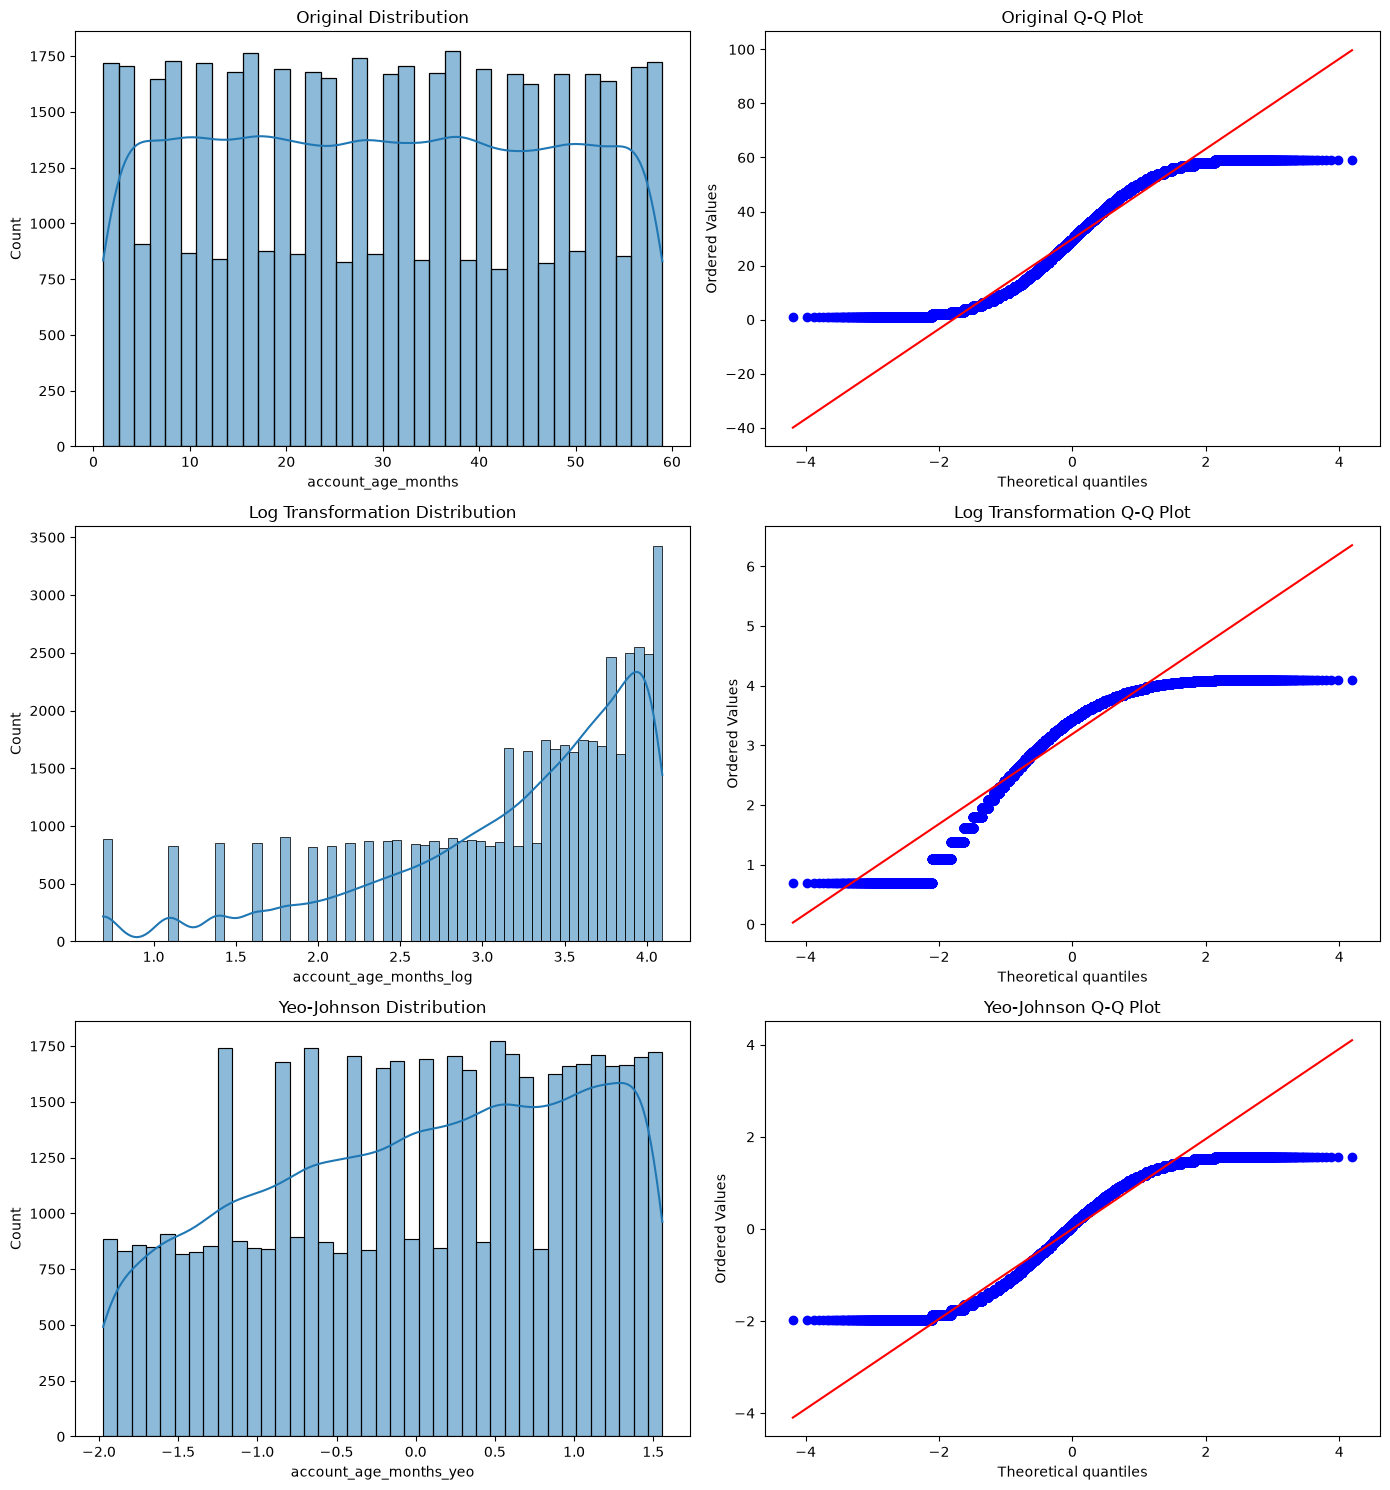

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

features = [
    "account_age_months",
    "account_age_months_log",
    "account_age_months_yeo"
]

titles = ["Original", "Log Transformation", "Yeo-Johnson"]

fig, ax = plt.subplots(3, 2, figsize=(14, 15))

for i, col in enumerate(features):

    # Distribution plot
    sns.histplot(
        netflix_data[col].dropna(),
        kde=True,
        ax=ax[i, 0]
    )

    ax[i, 0].set_title(f"{titles[i]} Distribution")

    # Q-Q plot
    stats.probplot(
        netflix_data[col].dropna(),
        dist="norm",
        plot=ax[i, 1]
    )

    ax[i, 1].set_title(f"{titles[i]} Q-Q Plot")

plt.tight_layout()
plt.show()

In [29]:
skew_comparison = pd.DataFrame({
    "Original": [netflix_data["account_age_months"].skew()],
    "Log": [netflix_data["account_age_months_log"].skew()],
    "Yeo-Johnson": [netflix_data["account_age_months_yeo"].skew()]
})

print(skew_comparison)

   Original       Log  Yeo-Johnson
0  0.011984 -1.171687    -0.234301


In [30]:
netflix_data["age_log"] = np.log1p(
    netflix_data["age"]
)

In [31]:
netflix_data["age_yeo"] = pt.fit_transform(
    netflix_data[["age"]]
)

In [32]:
skew_comparison = pd.DataFrame({
    "Original": [netflix_data["age"].skew()],
    "Log": [netflix_data["age_log"].skew()],
    "Yeo-Johnson": [netflix_data["age_yeo"].skew()]
})

print(skew_comparison)

   Original       Log  Yeo-Johnson
0  0.007921 -0.429383    -0.102369


In [33]:
netflix_data["monthly_fee_log"] = np.log1p(
    netflix_data["monthly_fee"]
)

In [34]:
netflix_data["monthly_fee_yeo"] = pt.fit_transform(
    netflix_data[["monthly_fee"]]
)

In [35]:
skew_comparison = pd.DataFrame({
    "Original": [netflix_data["monthly_fee"].skew()],
    "Log": [netflix_data["monthly_fee_log"].skew()],
    "Yeo-Johnson": [netflix_data["monthly_fee_yeo"].skew()]
})

print(skew_comparison)

   Original       Log  Yeo-Johnson
0 -0.292348 -0.431238    -0.214367


In [36]:
netflix_data["avg_watch_time_minutes_log"] = np.log1p(
    netflix_data["avg_watch_time_minutes"]
)

In [37]:
netflix_data["avg_watch_time_minutes_yeo"] = pt.fit_transform(
    netflix_data[["avg_watch_time_minutes"]]
)

In [38]:
netflix_data["watch_sessions_per_week_log"] = np.log1p(
    netflix_data["watch_sessions_per_week"]
)

In [39]:
netflix_data["watch_sessions_per_week_yeo"] = pt.fit_transform(
    netflix_data[["watch_sessions_per_week"]]
)

In [40]:
netflix_data["binge_watch_sessions_log"] = np.log1p(
    netflix_data["binge_watch_sessions"]
)

In [41]:
netflix_data["binge_watch_sessions_yeo"] = pt.fit_transform(
    netflix_data[["binge_watch_sessions"]]
)

In [42]:
netflix_data["completion_rate_log"] = np.log1p(
    netflix_data["completion_rate"]
)

In [43]:
netflix_data["completion_rate_yeo"] = pt.fit_transform(
    netflix_data[["completion_rate"]]
)

In [44]:
netflix_data["rating_given_log"] = np.log1p(
    netflix_data["rating_given"]
)

In [45]:
netflix_data["rating_given_yeo"] = pt.fit_transform(
    netflix_data[["rating_given"]]
)

In [46]:
netflix_data["content_interactions_log"] = np.log1p(
    netflix_data["content_interactions"]
)

In [47]:
netflix_data["content_interactions_yeo"] = pt.fit_transform(
    netflix_data[["content_interactions"]]
)

In [48]:
netflix_data["recommendation_click_rate_log"] = np.log1p(
    netflix_data["recommendation_click_rate"]
)

In [49]:
netflix_data["recommendation_click_rate_yeo"] = pt.fit_transform(
    netflix_data[["recommendation_click_rate"]]
)

In [50]:
netflix_data["days_since_last_login_log"] = np.log1p(
    netflix_data["days_since_last_login"]
)

In [51]:
netflix_data["days_since_last_login_yeo"] = pt.fit_transform(
    netflix_data[["days_since_last_login"]]
)

In [52]:
num_var

['age',
 'account_age_months',
 'monthly_fee',
 'avg_watch_time_minutes',
 'watch_sessions_per_week',
 'binge_watch_sessions',
 'completion_rate',
 'rating_given',
 'content_interactions',
 'recommendation_click_rate',
 'days_since_last_login']

In [53]:
num_var_log = ['age_log',
 'account_age_months_log',
 'monthly_fee_log',
 'avg_watch_time_minutes_log',
 'watch_sessions_per_week_log',
 'binge_watch_sessions_log',
 'completion_rate_log',
 'rating_given_log',
 'content_interactions_log',
 'recommendation_click_rate_log',
 'days_since_last_login_log']

In [54]:
num_var_yeo = ['age_yeo',
 'account_age_months_yeo',
 'monthly_fee_yeo',
 'avg_watch_time_minutes_yeo',
 'watch_sessions_per_week_yeo',
 'binge_watch_sessions_yeo',
 'completion_rate_yeo',
 'rating_given_yeo',
 'content_interactions_yeo',
 'recommendation_click_rate_yeo',
 'days_since_last_login_yeo']

In [55]:
def skew_comparison(num_var,num_var_log,num_var_yeo):
    
    skew_comparison_df = pd.DataFrame({
    "Original": [netflix_data[num_var].skew()],
    "Log": [netflix_data[num_var_log].skew()],
    "Yeo-Johnson": [netflix_data[num_var_yeo].skew()]
    })
    
    return skew_comparison_df

In [56]:
for col in range(len(num_var)):
    print(f"skew compariosn of {num_var[col]}")
    print(skew_comparison(num_var[col],num_var_log[col],num_var_yeo[col]))

skew compariosn of age
   Original       Log  Yeo-Johnson
0  0.007921 -0.429383    -0.102369
skew compariosn of account_age_months
   Original       Log  Yeo-Johnson
0  0.011984 -1.171687    -0.234301
skew compariosn of monthly_fee
   Original       Log  Yeo-Johnson
0 -0.292348 -0.431238    -0.214367
skew compariosn of avg_watch_time_minutes
   Original       Log  Yeo-Johnson
0 -0.008868 -1.108584    -0.228359
skew compariosn of watch_sessions_per_week
   Original       Log  Yeo-Johnson
0  0.000819 -0.846628    -0.192224
skew compariosn of binge_watch_sessions
   Original       Log  Yeo-Johnson
0  0.003289 -1.016221    -0.225255
skew compariosn of completion_rate
   Original       Log  Yeo-Johnson
0 -0.001427 -0.411084    -0.099929
skew compariosn of rating_given
   Original       Log  Yeo-Johnson
0   0.00516 -0.377103     -0.09029
skew compariosn of content_interactions
   Original       Log  Yeo-Johnson
0  0.018385 -1.342138    -0.255066
skew compariosn of recommendation_click_rate
 

In [57]:
netflix_data_final = netflix_data[num_var + cat_var].copy()

In [58]:
netflix_data_final

,age,account_age_months,monthly_fee,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,gender,country,devices_used,subscription_type,payment_method,primary_device,favorite_genre,churned
0,56,17,15.99,220,17,3,60,1.7,5,66,16,Male,India,1,Standard,PayPal,Laptop,Sci-Fi,No
1,46,20,12.99,76,15,4,71,4.6,7,78,14,Female,USA,2,Standard,PayPal,Tablet,Documentary,No
2,32,25,15.99,215,6,13,33,2.0,27,29,41,Other,USA,2,Basic,PayPal,Tablet,Comedy,No
3,60,37,12.99,280,4,9,58,1.2,9,23,22,Male,Canada,3,Standard,PayPal,Smart TV,Action,No
4,25,23,12.99,261,15,9,64,1.3,49,56,54,Male,Brazil,3,Premium,PayPal,Mobile,Horror,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,60,30,15.99,178,19,1,45,1.8,13,43,8,Female,Japan,1,Standard,UPI,Tablet,Documentary,No
49996,46,39,12.99,95,15,5,77,2.1,46,11,30,Other,Brazil,3,Standard,PayPal,Smart TV,Comedy,Yes
49997,19,53,7.99,118,18,4,44,2.3,26,17,16,Male,UK,3,Basic,Credit Card,Tablet,Thriller,No
49998,43,19,7.99,280,2,4,44,2.4,12,4,31,Female,UK,1,Standard,PayPal,Laptop,Thriller,No


In [59]:
def box_plot(var):

    plt.figure(figsize=(10, 4))

    sns.boxplot(netflix_data_final[var])

    plt.title(f"Boxplot of {var}")
    plt.xlabel(var)

    plt.show()

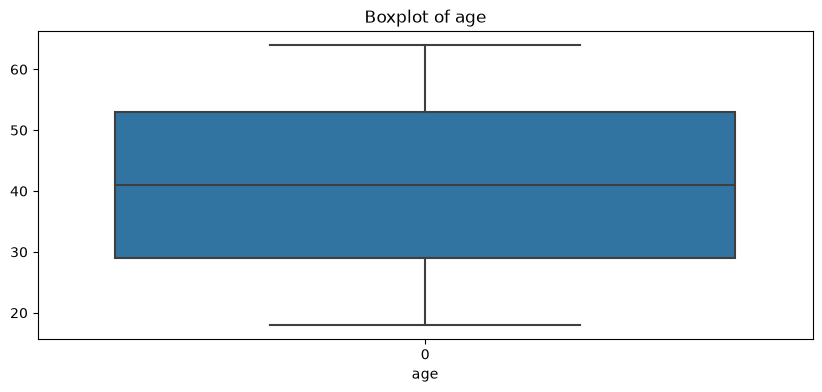

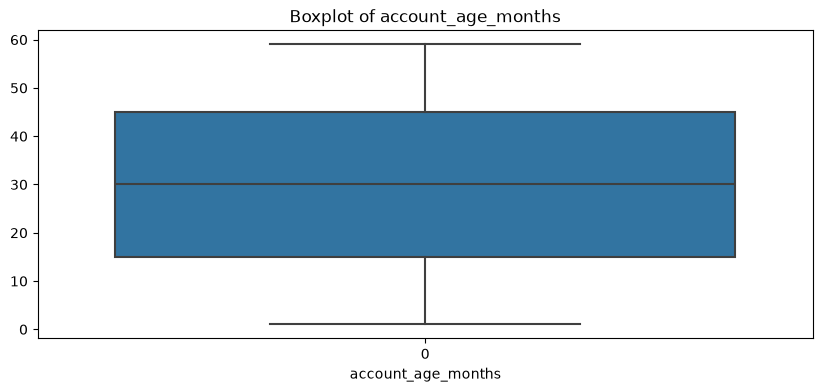

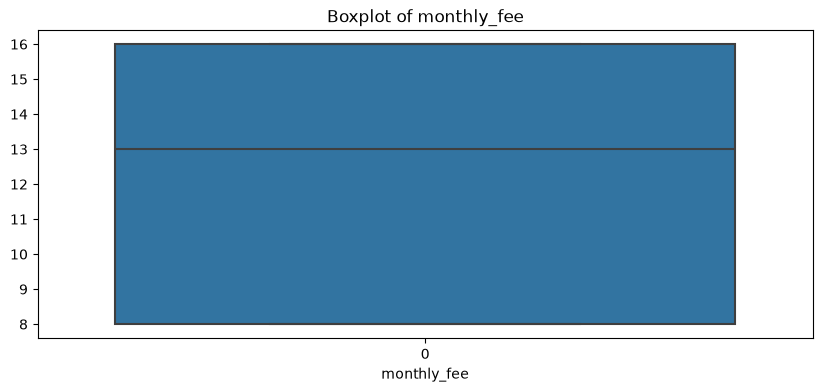

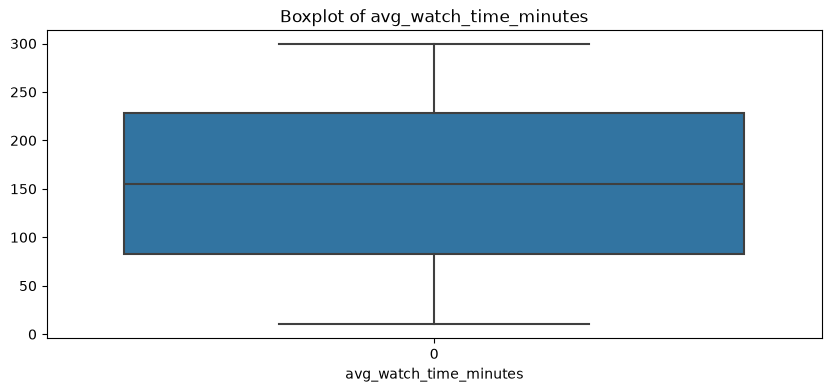

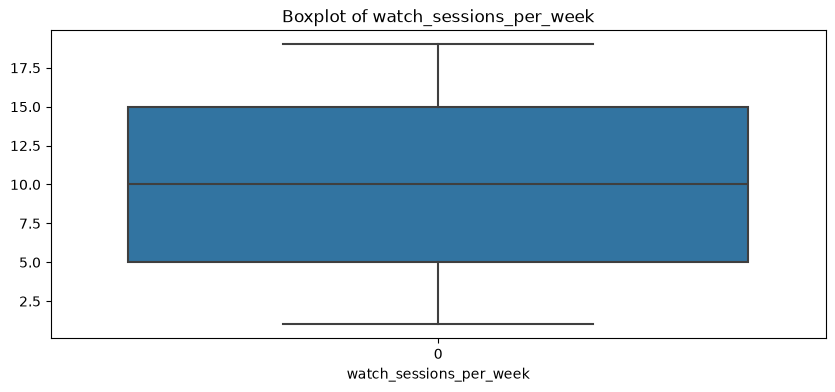

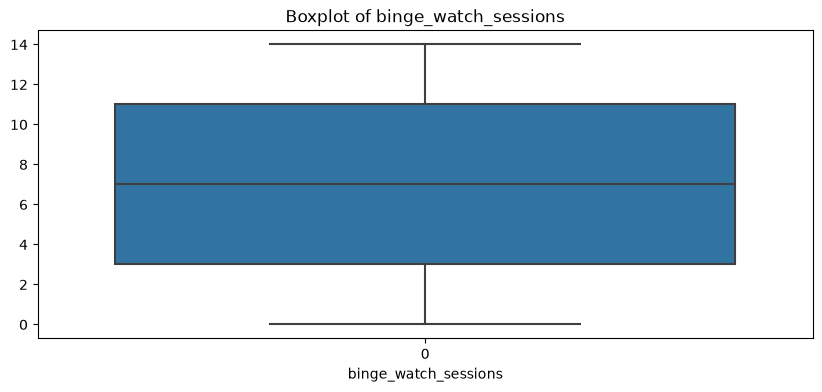

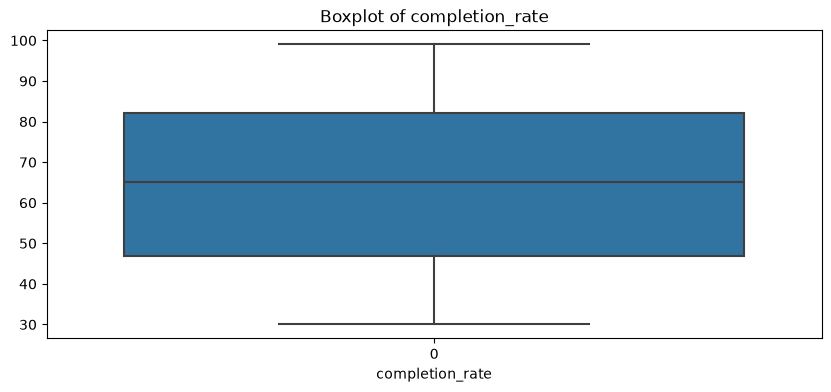

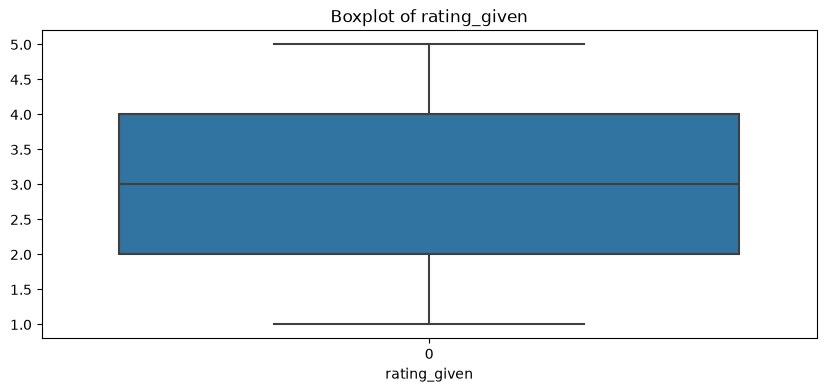

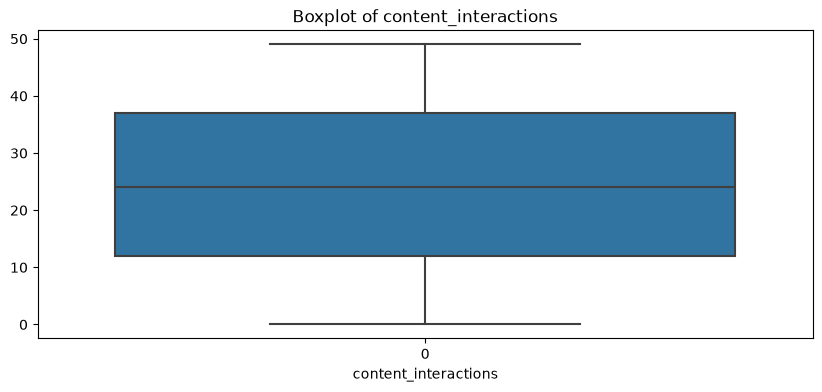

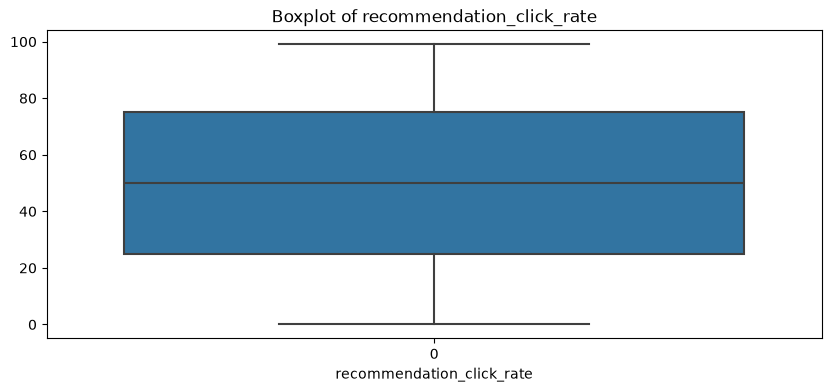

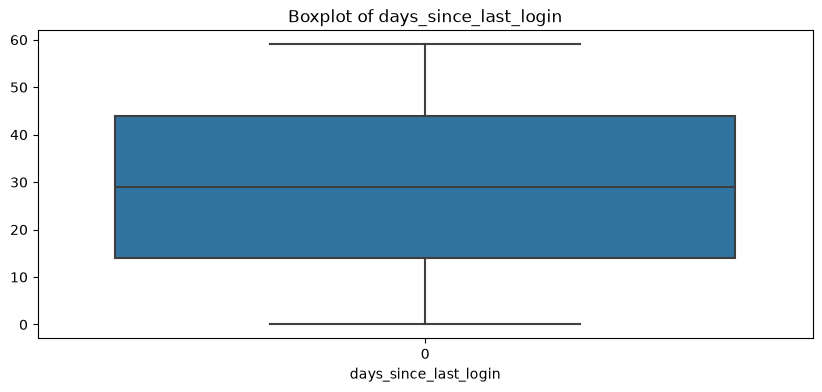

In [60]:
for col in range(len(num_var)):
    box_plot(num_var[col])

In [61]:
from sklearn.preprocessing import LabelEncoder , StandardScaler

In [62]:
cat_var

['gender',
 'country',
 'devices_used',
 'subscription_type',
 'payment_method',
 'primary_device',
 'favorite_genre',
 'churned']

In [63]:
cat_var1 = ['gender',
 'country',
 'subscription_type',
 'payment_method',
 'primary_device',
 'favorite_genre',
 'churned']

In [64]:
# Dictionary to store individual encoders
label_encoders = {}

for col in cat_var1:

    le = LabelEncoder()

    netflix_data_final[col] = le.fit_transform(netflix_data_final[col])

    label_encoders[col] = le

In [65]:
label_encoders['gender'].classes_

array(['Female', 'Male', 'Other'], dtype=object)

In [66]:
for col, encoder in label_encoders.items():

    mapping = dict(zip(encoder.classes_,
                       encoder.transform(encoder.classes_)))

    print(f"\n{col}: {mapping}")


gender: {'Female': 0, 'Male': 1, 'Other': 2}

country: {'Australia': 0, 'Brazil': 1, 'Canada': 2, 'France': 3, 'Germany': 4, 'India': 5, 'Japan': 6, 'Spain': 7, 'UK': 8, 'USA': 9}

subscription_type: {'Basic': 0, 'Premium': 1, 'Standard': 2}

payment_method: {'Credit Card': 0, 'Debit Card': 1, 'PayPal': 2, 'UPI': 3}

primary_device: {'Laptop': 0, 'Mobile': 1, 'Smart TV': 2, 'Tablet': 3}

favorite_genre: {'Action': 0, 'Comedy': 1, 'Documentary': 2, 'Drama': 3, 'Horror': 4, 'Romance': 5, 'Sci-Fi': 6, 'Thriller': 7}

churned: {'No': 0, 'Yes': 1}


In [67]:
netflix_data_final

,age,account_age_months,monthly_fee,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,gender,country,devices_used,subscription_type,payment_method,primary_device,favorite_genre,churned
0,56,17,15.99,220,17,3,60,1.7,5,66,16,1,5,1,2,2,0,6,0
1,46,20,12.99,76,15,4,71,4.6,7,78,14,0,9,2,2,2,3,2,0
2,32,25,15.99,215,6,13,33,2.0,27,29,41,2,9,2,0,2,3,1,0
3,60,37,12.99,280,4,9,58,1.2,9,23,22,1,2,3,2,2,2,0,0
4,25,23,12.99,261,15,9,64,1.3,49,56,54,1,1,3,1,2,1,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,60,30,15.99,178,19,1,45,1.8,13,43,8,0,6,1,2,3,3,2,0
49996,46,39,12.99,95,15,5,77,2.1,46,11,30,2,1,3,2,2,2,1,1
49997,19,53,7.99,118,18,4,44,2.3,26,17,16,1,8,3,0,0,3,7,0
49998,43,19,7.99,280,2,4,44,2.4,12,4,31,0,8,1,2,2,0,7,0


## Handle Class imbalance 

In [68]:
from imblearn.over_sampling import SMOTE

In [69]:
input_data = netflix_data_final.iloc[:,:-1]

In [70]:
input_data

,age,account_age_months,monthly_fee,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,gender,country,devices_used,subscription_type,payment_method,primary_device,favorite_genre
0,56,17,15.99,220,17,3,60,1.7,5,66,16,1,5,1,2,2,0,6
1,46,20,12.99,76,15,4,71,4.6,7,78,14,0,9,2,2,2,3,2
2,32,25,15.99,215,6,13,33,2.0,27,29,41,2,9,2,0,2,3,1
3,60,37,12.99,280,4,9,58,1.2,9,23,22,1,2,3,2,2,2,0
4,25,23,12.99,261,15,9,64,1.3,49,56,54,1,1,3,1,2,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,60,30,15.99,178,19,1,45,1.8,13,43,8,0,6,1,2,3,3,2
49996,46,39,12.99,95,15,5,77,2.1,46,11,30,2,1,3,2,2,2,1
49997,19,53,7.99,118,18,4,44,2.3,26,17,16,1,8,3,0,0,3,7
49998,43,19,7.99,280,2,4,44,2.4,12,4,31,0,8,1,2,2,0,7


In [71]:
target_data = netflix_data_final["churned"]

In [72]:
target_data

0        0
1        0
2        0
3        0
4        0
        ..
49995    0
49996    1
49997    0
49998    0
49999    1
Name: churned, Length: 50000, dtype: int32

In [73]:
smote = SMOTE(random_state=42)
input_data_smote , target_data_smote = smote.fit_resample(input_data , target_data)

In [74]:
from sklearn.model_selection import train_test_split

In [75]:
x_train , x_test , y_train , y_test = train_test_split(input_data_smote , target_data_smote , test_size = 0.2 , random_state = 42)

In [76]:
x_train.shape , x_test.shape

((64057, 18), (16015, 18))

## PCA

In [77]:
from sklearn.decomposition import PCA

In [78]:
pca = PCA(n_components = None)
x_train_pca = pca.fit_transform(x_train)
x_test_pca = pca.transform(x_test)

In [79]:
pca.explained_variance_.shape

(18,)

In [80]:
pca.components_.shape

(18, 18)

In [81]:
np.cumsum(pca.explained_variance_ratio_)

array([0.75781816, 0.84644976, 0.88946821, 0.92104935, 0.95158205,
       0.97341804, 0.99236708, 0.99527414, 0.99708754, 0.99813598,
       0.99893087, 0.99943275, 0.9995588 , 0.99968406, 0.99980051,
       0.99987158, 0.99993622, 1.        ])

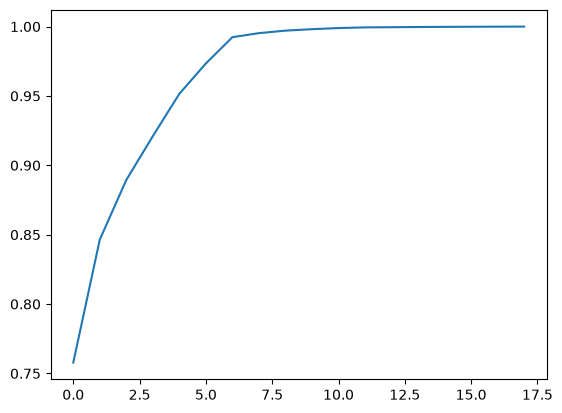

In [82]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))

In [83]:
x_train_pca.shape , x_test_pca.shape

((64057, 18), (16015, 18))

In [84]:
# Dictionary to store individual scalers
scalers = {}

for col in num_var:

    scaler = StandardScaler()

    x_train[col] = scaler.fit_transform(x_train[[col]])

    scalers[col] = scaler

In [85]:
scalers['monthly_fee'].mean_

array([12.30983769])

In [86]:
scalers['monthly_fee'].scale_

array([3.11500226])

In [87]:
for col in num_var:
    x_test[col] = scalers[col].transform(x_test[[col]])

In [88]:
x_train[num_var].describe()

,age,account_age_months,monthly_fee,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login
count,6.405700e+04,6.405700e+04,6.405700e+04,6.405700e+04,6.405700e+04,6.405700e+04,6.405700e+04,6.405700e+04,6.405700e+04,6.405700e+04,6.405700e+04
mean,7.054735e-17,-1.247890e-17,-5.191220e-16,-1.477501e-16,7.343136e-17,1.264528e-17,3.190160e-16,-3.810223e-16,2.839642e-17,3.749215e-17,-8.652034e-17
std,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00
min,-1.720382e+00,-1.699839e+00,-1.386785e+00,-1.724112e+00,-1.695118e+00,-1.664910e+00,-1.720626e+00,-1.854131e+00,-1.692783e+00,-1.719671e+00,-1.711233e+00
25%,-8.897327e-01,-8.669523e-01,-1.386785e+00,-8.643355e-01,-9.241506e-01,-9.326728e-01,-8.685435e-01,-8.350932e-01,-8.488072e-01,-8.816621e-01,-8.923615e-01
50%,1.642962e-02,-3.406595e-02,2.183505e-01,-4.558468e-03,3.955814e-02,4.364366e-02,-1.646077e-02,-1.334820e-03,-4.830978e-03,-8.735669e-03,-1.499868e-02
75%,8.470784e-01,8.583123e-01,1.181432e+00,8.671599e-01,8.105251e-01,7.758810e-01,8.857445e-01,8.324236e-01,8.391452e-01,8.641907e-01,8.623641e-01
max,1.753241e+00,1.750691e+00,1.181432e+00,1.726937e+00,1.774234e+00,1.752197e+00,1.737827e+00,1.851462e+00,1.753453e+00,1.737117e+00,1.739727e+00


In [89]:
x_test[num_var].describe()

,age,account_age_months,monthly_fee,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login
count,16015.000000,16015.000000,16015.000000,16015.000000,16015.000000,16015.000000,16015.000000,16015.000000,16015.000000,16015.000000,16015.000000
mean,-0.006321,-0.009690,0.012762,-0.004123,-0.007270,-0.003724,0.007995,-0.010525,-0.011023,0.006014,0.011144
std,0.996553,0.999708,1.004040,0.998651,1.003995,1.001329,0.996456,0.993522,1.001660,0.998645,0.998046
min,-1.720382,-1.699839,-1.386785,-1.724112,-1.695118,-1.664910,-1.720626,-1.854131,-1.692783,-1.719671,-1.711233
25%,-0.889733,-0.866952,-1.386785,-0.864335,-0.924151,-0.932673,-0.868544,-0.835093,-0.919139,-0.846745,-0.833871
50%,0.016430,-0.034066,0.218351,-0.004558,0.039558,0.043644,0.033662,-0.001335,-0.004831,-0.008736,-0.014999
75%,0.847078,0.858312,1.181432,0.867160,0.810525,0.775881,0.885745,0.817405,0.839145,0.864191,0.862364
max,1.753241,1.750691,1.181432,1.726937,1.774234,1.752197,1.737827,1.851462,1.753453,1.737117,1.739727


In [90]:
x_train.head()

,age,account_age_months,monthly_fee,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,gender,country,devices_used,subscription_type,payment_method,primary_device,favorite_genre
29296,0.016430,-0.331525,1.181432,-1.389755,1.196009,1.752197,0.284274,1.110343,-0.497150,-0.218238,-1.243307,1,5,1,1,3,0,7
21654,-0.436652,-0.153050,-1.386785,1.285107,1.003267,0.043644,0.083784,1.851462,1.683121,-0.532492,1.739727,2,5,1,2,3,1,0
57360,-0.965246,-0.747969,-1.215586,0.389506,-1.695118,0.531802,-0.016461,-0.989504,1.261133,0.200767,-0.599907,0,0,2,2,1,3,3
2337,-1.569355,-0.510001,0.218351,-0.374740,1.774234,-0.688594,1.386970,0.832424,0.487488,-1.684754,-1.477270,1,1,2,0,3,1,6
70552,0.847078,-0.034066,1.066303,1.667230,-1.309634,0.775881,-1.319646,-1.353664,0.698483,1.527615,1.037837,1,4,2,2,1,0,5


## Fit Logistic Regression 

In [91]:
from sklearn.linear_model import LogisticRegression

In [92]:
lr = LogisticRegression()

In [93]:
lr.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [94]:
y_pred_lr = lr.predict(x_test)

In [95]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,roc_curve,auc

In [96]:
accuracy_score(y_test,y_pred_lr)

0.6470184202310334

[[5037 2914]
 [2739 5325]]


Text(50.83333333333332, 0.5, 'Actual Values')

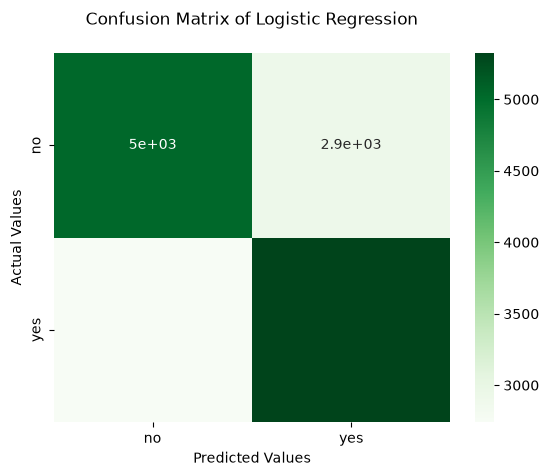

In [97]:
cm = confusion_matrix(y_test,y_pred_lr)
print(cm)  ## print confusion matrix
sns.heatmap(cm,annot=True,cmap='Greens',xticklabels=['no','yes'],yticklabels=['no','yes'])  ## graphically show confusion matrix
plt.title('Confusion Matrix of Logistic Regression\n')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

In [98]:
print(classification_report(y_pred_lr,y_test))

              precision    recall  f1-score   support

           0       0.63      0.65      0.64      7776
           1       0.66      0.65      0.65      8239

    accuracy                           0.65     16015
   macro avg       0.65      0.65      0.65     16015
weighted avg       0.65      0.65      0.65     16015



In [99]:
y_prob_lr = lr.predict_proba(x_test)[:,1]

In [100]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)

roc_auc = auc(fpr, tpr)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.6938575785615466


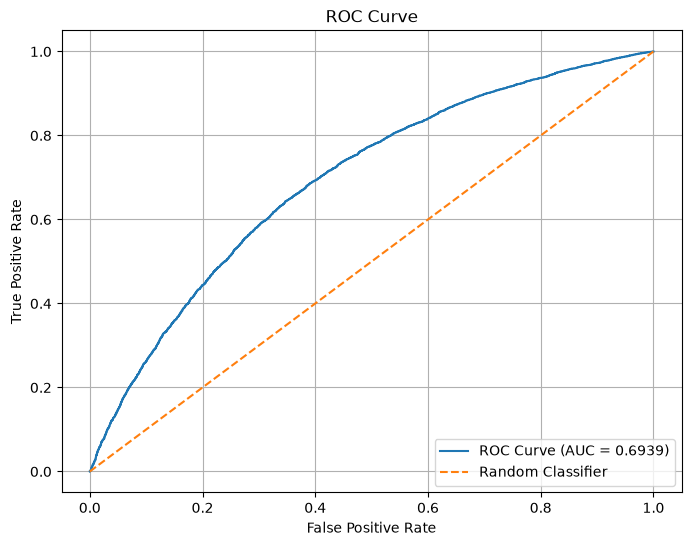

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid()
plt.show()

## Fit Random Forest Classifier

In [102]:
from sklearn.ensemble import RandomForestClassifier

In [103]:
rfc = RandomForestClassifier()

In [104]:
criterion =['gini','entropy']
max_depth = [1,3,5,6,7,8,9,10,12,13,15,None]
max_features = ["sqrt","log2",None]

In [105]:
para_grid = {
    "criterion" : criterion,
    "max_depth" : max_depth,
    "max_features" : max_features
}

In [106]:
from sklearn.model_selection import GridSearchCV

In [107]:
gridcv = GridSearchCV(estimator=rfc,
                     param_grid=para_grid,
                     cv=3,
                     verbose=True)

In [108]:
gridcv.fit(x_train,y_train)

Fitting 3 folds for each of 72 candidates, totalling 216 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [1, 3, ...], 'max_features': ['sqrt', 'log2', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_g

In [109]:
gridcv.best_score_ 

0.8126200518851254

In [110]:
gridcv.best_params_

{'criterion': 'entropy', 'max_depth': None, 'max_features': None}

In [111]:
rfc = RandomForestClassifier(criterion="entropy")

In [112]:
rfc.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `met

In [113]:
y_pred_rfc = rfc.predict(x_test)

In [114]:
accuracy_score(y_test , y_pred_rfc)

0.8290977208866688

In [115]:
print(classification_report(y_test,y_pred_rfc))

              precision    recall  f1-score   support

           0       0.78      0.92      0.84      7951
           1       0.91      0.74      0.81      8064

    accuracy                           0.83     16015
   macro avg       0.84      0.83      0.83     16015
weighted avg       0.84      0.83      0.83     16015



[[7342  609]
 [2128 5936]]


Text(50.83333333333332, 0.5, 'Actual Values')

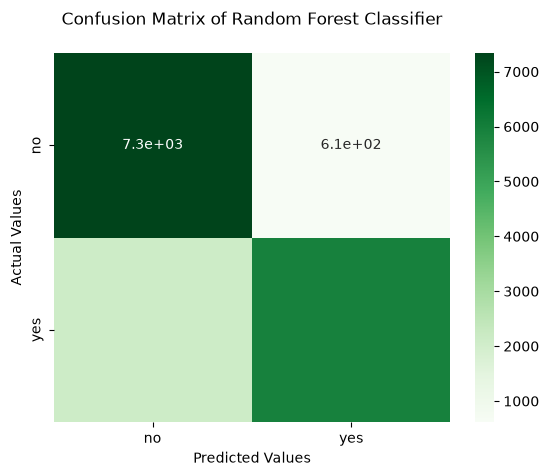

In [116]:
cm = confusion_matrix(y_test,y_pred_rfc)
print(cm)  ## print confusion matrix
sns.heatmap(cm,annot=True,cmap='Greens',xticklabels=['no','yes'],yticklabels=['no','yes'])  ## graphically show confusion matrix
plt.title('Confusion Matrix of Random Forest Classifier\n')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

In [117]:
rfc.feature_importances_

array([0.05682012, 0.05874558, 0.16284262, 0.06621957, 0.05062838,
       0.04783768, 0.06070422, 0.07014648, 0.05823397, 0.06263344,
       0.05855055, 0.02919275, 0.04478468, 0.03045764, 0.03048961,
       0.03573671, 0.0348787 , 0.04109729])

In [118]:
importance = pd.DataFrame({
    "Features": x_train.columns,
    "Importance": rfc.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                     Features  Importance
2                 monthly_fee    0.162843
7                rating_given    0.070146
3      avg_watch_time_minutes    0.066220
9   recommendation_click_rate    0.062633
6             completion_rate    0.060704
1          account_age_months    0.058746
10      days_since_last_login    0.058551
8        content_interactions    0.058234
0                         age    0.056820
4     watch_sessions_per_week    0.050628
5        binge_watch_sessions    0.047838
12                    country    0.044785
17             favorite_genre    0.041097
15             payment_method    0.035737
16             primary_device    0.034879
14          subscription_type    0.030490
13               devices_used    0.030458
11                     gender    0.029193


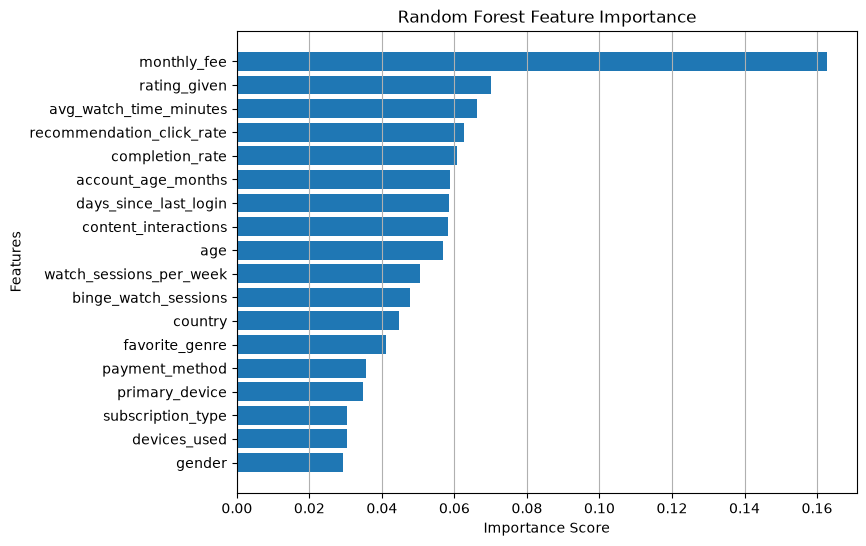

In [119]:
plt.figure(figsize=(8, 6))

plt.barh(
    importance["Features"],
    importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.grid(axis="x")
plt.show()

In [120]:
y_prob_rfc = rfc.predict_proba(x_test)[:,1]

In [121]:
y_prob_rfc

array([0.38, 0.23, 0.34, ..., 0.72, 0.76, 0.49])

In [122]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rfc)

roc_auc = auc(fpr, tpr)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8820377428315895


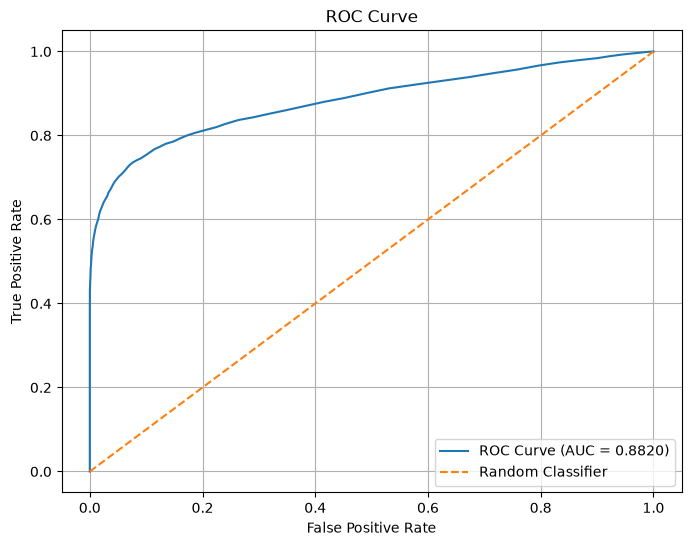

In [123]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid()
plt.show()

## Fit xgboost

In [124]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [125]:
import xgboost as xgb
from xgboost import XGBClassifier

In [126]:
param_grid = {
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "min_child_weight": [1, 3],
    "gamma": [0, 0.1, 0.2],
    "subsample": [0.8, 1.0]
}

In [127]:
xgb_model=XGBClassifier()

In [128]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_search.fit(x_train, y_train)

Fitting 3 folds for each of 144 candidates, totalling 432 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 3], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluatio

In [129]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation ROC-AUC:")
print(grid_search.best_score_)

Best Parameters:
{'gamma': 0, 'learning_rate': 0.1, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 1.0}

Best Cross Validation ROC-AUC:
0.8599520112449185


In [130]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    max_depth=6,
    learning_rate=0.1,
    n_estimators=100,
    gamma=0,
    min_child_weight = 1,
    random_state=42,
    eval_metric="logloss"
)

In [131]:
xgb_model.fit(x_train,y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [132]:
y_pred_xgb = xgb_model.predict(x_test)

In [133]:
accuracy_score(y_pred_xgb,y_test)

0.8185451139556665

In [134]:
print(classification_report(y_test,y_pred_xgb))

              precision    recall  f1-score   support

           0       0.76      0.93      0.84      7951
           1       0.91      0.71      0.80      8064

    accuracy                           0.82     16015
   macro avg       0.83      0.82      0.82     16015
weighted avg       0.83      0.82      0.82     16015



[[7379  572]
 [2334 5730]]


Text(50.83333333333332, 0.5, 'Actual Values')

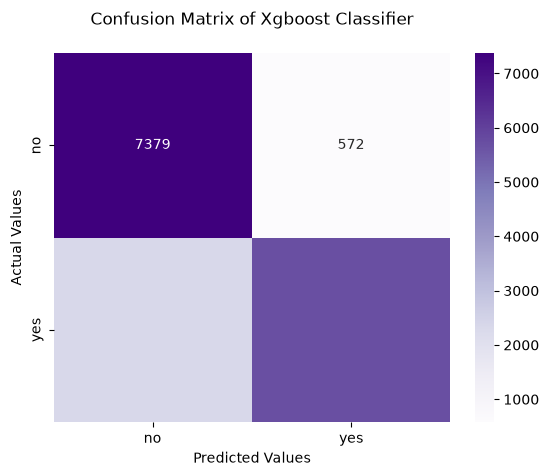

In [135]:
cm = confusion_matrix(y_test,y_pred_xgb)
print(cm)  ## print confusion matrix
sns.heatmap(cm,annot=True,fmt="d",cmap='Purples',xticklabels=['no','yes'],yticklabels=['no','yes'])  ## graphically show confusion matrix
plt.title('Confusion Matrix of Xgboost Classifier\n')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

In [137]:
y_prob_xgb = xgb_model.predict_proba(x_test)[:,1]

In [138]:
y_prob_xgb

array([0.42821988, 0.237126  , 0.34572634, ..., 0.5169143 , 0.55778766,
       0.45137775], dtype=float32)

In [139]:
roc_auc_score(y_test,y_prob_xgb)

0.8673163506562018

In [140]:
roc_curve(y_test,y_prob_xgb)

(array([0.       , 0.       , 0.       , ..., 0.9987423, 1.       ,
        1.       ]),
 array([0.00000000e+00, 1.24007937e-04, 1.31448413e-02, ...,
        9.99751984e-01, 9.99751984e-01, 1.00000000e+00]),
 array([       inf, 0.99600369, 0.99370003, ..., 0.07201734, 0.06164188,
        0.05093657]))

In [141]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_xgb)

roc_auc = auc(fpr, tpr)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8673163506562018


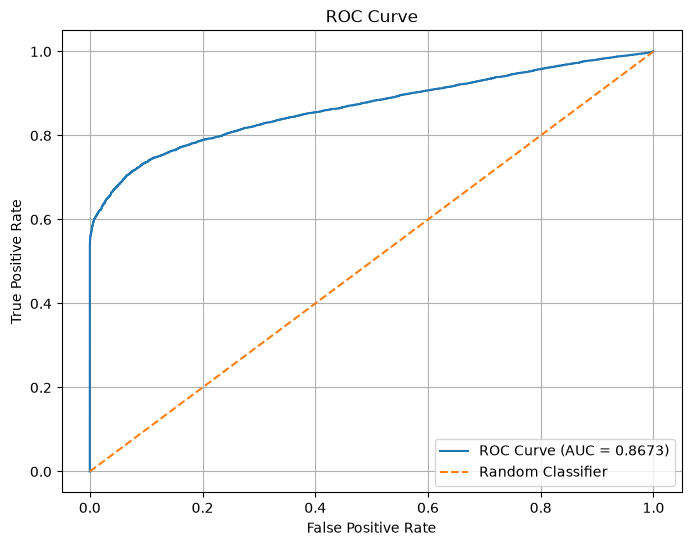

In [142]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid()
plt.show()

## SHAP Explainer

In [143]:
import shap

In [144]:
model = rfc

In [145]:
import shap

# Background dataset
background = x_train.sample(
    n=min(100, len(x_train)),
    random_state=42
)

# Data to explain
X_explain = x_test.sample(
    n=min(200, len(x_test)),
    random_state=42
)

# Create explainer
explainer = shap.TreeExplainer(
    model,
    data=background,
    feature_perturbation="interventional"
)

# Calculate SHAP values
shap_values = explainer(
    X_explain,
    check_additivity=False
)

 99%|===================| 395/400 [00:47<00:00]        

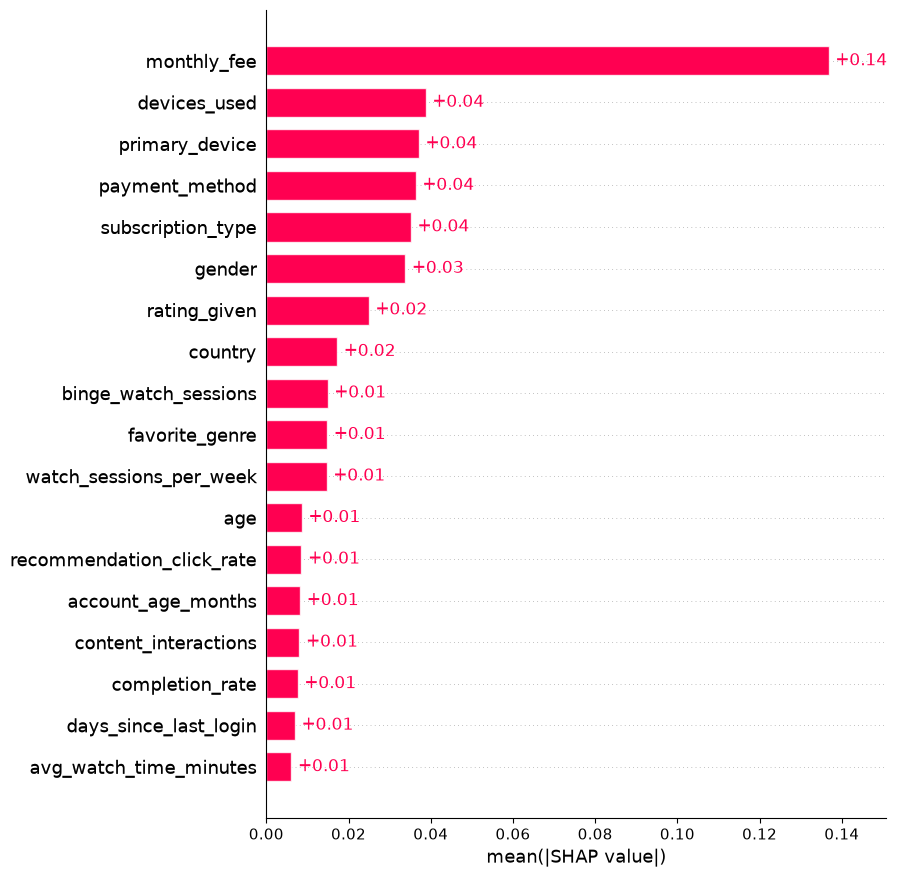

In [146]:
# For binary classification, select class 1 (Churn)
if len(shap_values.shape) == 3:
    shap_churn = shap_values[..., 1]
else:
    shap_churn = shap_values

plt.figure(figsize=(10, 6))

shap.plots.bar(
    shap_churn,
    max_display=18
)



In [147]:
print(type(shap_values))
print(shap_values.values.shape)
print(X_explain.shape)

<class 'shap._explanation.Explanation'>
(200, 18, 2)
(200, 18)


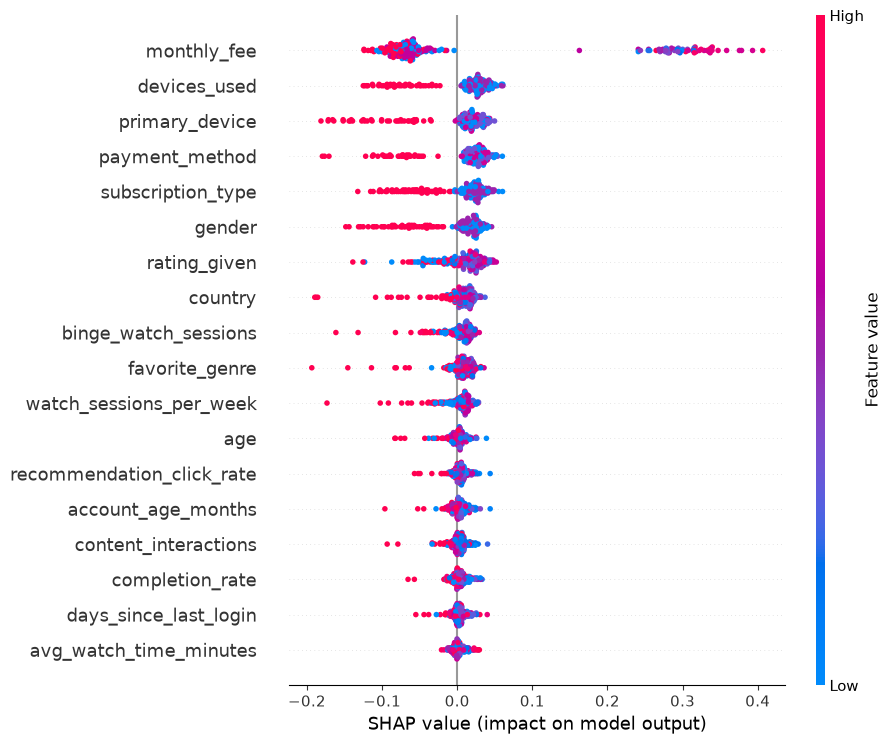

In [148]:
shap.plots.beeswarm(
    shap_churn,
    max_display=18
)

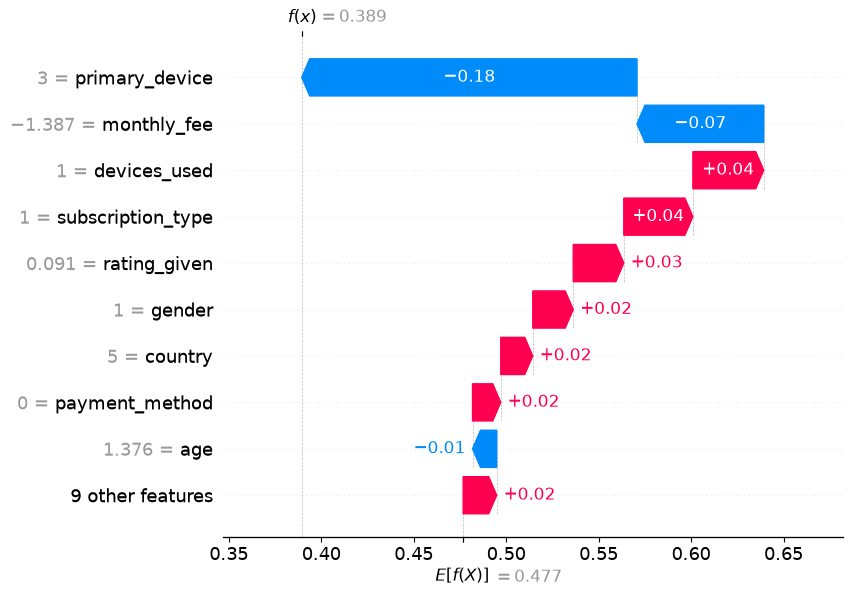

In [149]:
shap.plots.waterfall(
    shap_churn[0]
)

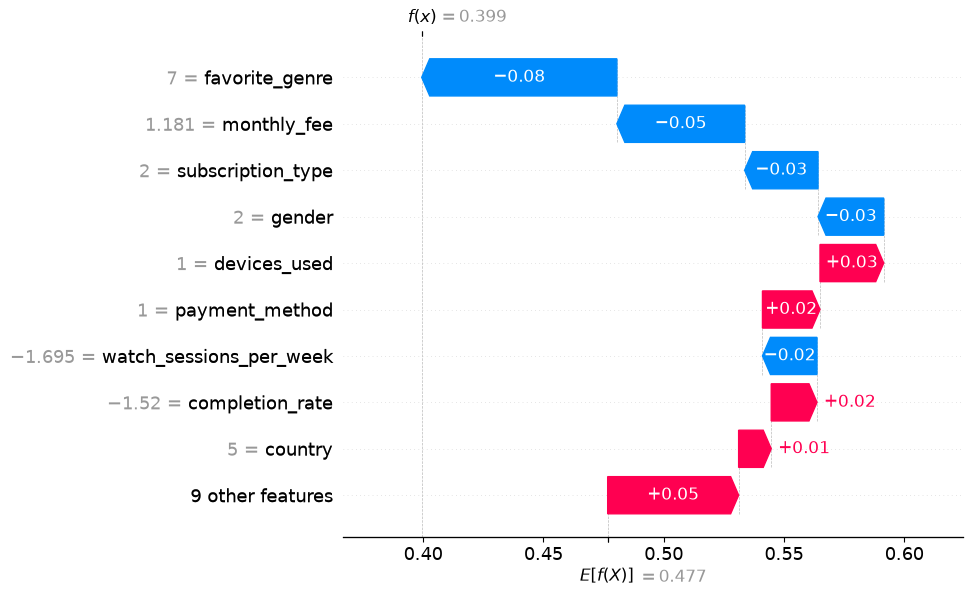

In [150]:
shap.plots.waterfall(
    shap_churn[10]
)

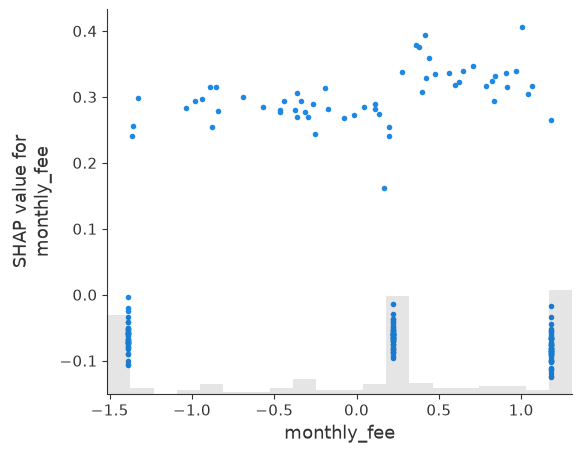

In [151]:
shap.plots.scatter(
    shap_churn[:, "monthly_fee"]
)

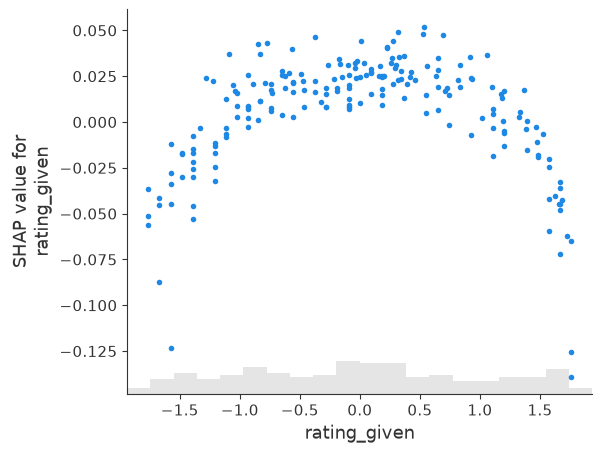

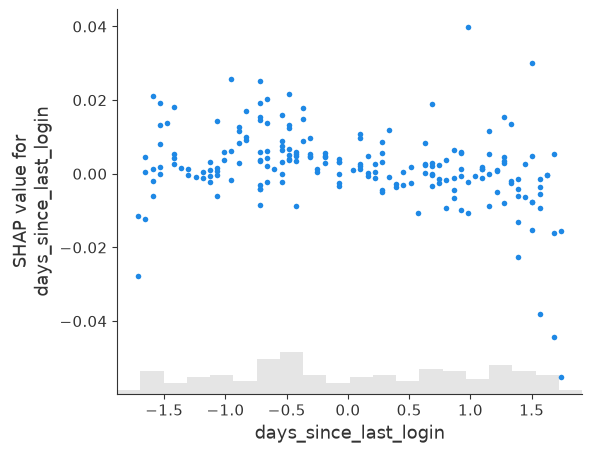

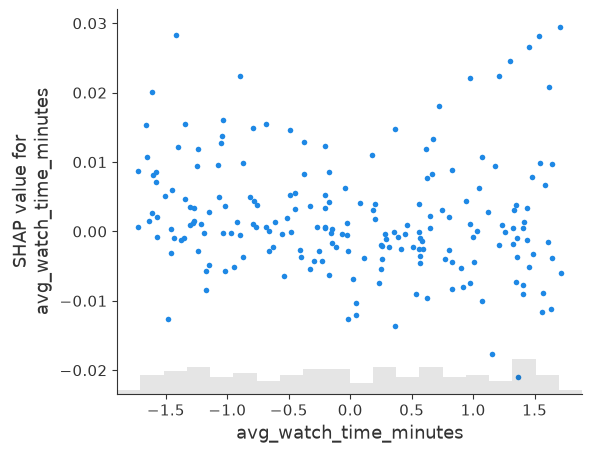

In [152]:
shap.plots.scatter(
    shap_churn[:, "rating_given"]
)

shap.plots.scatter(
    shap_churn[:, "days_since_last_login"]
)

shap.plots.scatter(
    shap_churn[:, "avg_watch_time_minutes"]
)

In [153]:
shap_importance = pd.DataFrame({
    "Feature": x_test.columns,
    "SHAP Importance": np.abs(
        shap_churn.values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="SHAP Importance",
    ascending=False
)

print(shap_importance)

                      Feature  SHAP Importance
2                 monthly_fee         0.136800
13               devices_used         0.038773
16             primary_device         0.037103
15             payment_method         0.036343
14          subscription_type         0.035159
11                     gender         0.033797
7                rating_given         0.024920
12                    country         0.017229
5        binge_watch_sessions         0.014908
17             favorite_genre         0.014794
4     watch_sessions_per_week         0.014675
0                         age         0.008628
9   recommendation_click_rate         0.008550
1          account_age_months         0.008239
8        content_interactions         0.008055
6             completion_rate         0.007625
10      days_since_last_login         0.006956
3      avg_watch_time_minutes         0.006096


## MLFlow

In [154]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [155]:
import mlflow

In [161]:
mlflow.is_tracking_uri_set()

True

In [157]:
models = {
    "Random Forest": rfc,
    "XGBoost": xgb_model
}

In [158]:
from mlflow.models import infer_signature

In [160]:
## set the tracking uri
mlflow.set_tracking_uri("http://127.0.0.1:5000")

## set an experiment name
mlflow.set_experiment("Netflix customer churn prediction")

## mlflow logging starts from here
for name , model in models.items():
    with mlflow.start_run(run_name=name):
        
        ## model name 
        mlflow.log_param("model_name",name)
        
        ## model parameters
        mlflow.log_params(model.get_params())
        
        ## predictions
        y_pred = model.predict(x_test)
        y_prob = model.predict_proba(x_test)[:,1]
        
        # Evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        roc_auc = roc_auc_score(y_test, y_prob)
        
        ## log metric
        mlflow.log_metric("accuracy",accuracy)
        mlflow.log_metric("precision",precision)
        mlflow.log_metric("recall",recall)
        mlflow.log_metric("F1",f1)
        mlflow.log_metric("roc_auc",roc_auc)
        
        print(f"Model: {name}")
        print("Accuracy:", accuracy)
        print("Precision:", precision)
        print("Recall:", recall)
        print("F1 Score:", f1)
        print("ROC AUC:", roc_auc)
        
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
        plt.title(f"Confusion Matrix - {name}")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")

        plt.tight_layout()

        plt.savefig("confusion_matrix.png")
        mlflow.log_artifact("confusion_matrix.png")
        plt.close()
        
        signature = infer_signature(x_test,y_pred)
        
          # Check whether the model is XGBoost
        if isinstance(model, XGBClassifier):

            mlflow.xgboost.log_model(
                xgb_model=model,
                name=f"{name}_model",
                model_format="ubj",
                signature=signature
            )

        else:

            mlflow.sklearn.log_model(
                sk_model=model,
                name=f"{name}_model",
                serialization_format="pickle",
                signature=signature
            )

        print(f"{name} logged successfully!")


Model: Random Forest
Accuracy: 0.8290977208866688
Precision: 0.906951871657754
Recall: 0.7361111111111112
F1 Score: 0.8126497364638237
ROC AUC: 0.8820377428315895


C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/05 23:16:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbit

Random Forest logged successfully!
🏃 View run Random Forest at: http://127.0.0.1:5000/#/experiments/3/runs/7922df19397749dfa095a261680528bf
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
Model: XGBoost
Accuracy: 0.8185451139556665
Precision: 0.9092351634401777
Recall: 0.7105654761904762
F1 Score: 0.79771683140749
ROC AUC: 0.8673163506562018


C:\Users\Saikat Maiti\Downloads\Anaconda\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


XGBoost logged successfully!
🏃 View run XGBoost at: http://127.0.0.1:5000/#/experiments/3/runs/aa582d3fae8547ae8835eb04e3d828d7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


## Saved Model

In [452]:
import pickle

In [453]:
# Save trained model
with open("random_forest_model.pkl", "wb") as file:
    pickle.dump(rfc, file)

print("Model saved successfully!")

Model saved successfully!


In [454]:
with open('label_encoders.pkl', 'wb') as file:
    pickle.dump(label_encoders, file)

In [455]:
with open('standard_scalers.pkl', 'wb') as file:
    pickle.dump(scalers, file)